# Lección 4: Redes y análisis topológico de comunidades microbianas

## Curso de Invierno — Microbioma de la rizósfera

### Notebook maestro del instructor

⏱ **Duración estimada:** ~3.5 h, incluido un descanso de 10 min.

Este notebook sigue la misma secuencia que `cap04_TDA.qmd`. Contiene la explicación, todo el código ejecutable y las soluciones de los ejercicios. Cada celda debe funcionar al ejecutarse de arriba hacia abajo.

## Objetivos de aprendizaje

1. Construir redes de similitud entre muestras a partir de Bray-Curtis.
2. Aplicar homología persistente a matrices de disimilitud.
3. Construir redes de coocurrencia exploratorias a partir de correlación de Spearman.
4. Comparar diagramas de persistencia entre países con distancia de Wasserstein.
5. Distinguir observaciones topológicas de afirmaciones ecológicas causales.


---

## 🔧 Setup y carga de datos (~10 min)


In [1]:
# Propósito: detectar si el notebook corre en Colab o localmente y preparar los datos.
# En ambos casos, los resultados se guardan en una carpeta separada para no modificar los archivos de entrada.
# Detección de entorno y preparación reproducible de datos
import os
import sys
import zipfile
import urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
LESSON = "leccion_4_tda"
SUBSET_URL = (
    "https://github.com/MicroAgroBiome/"
    "MicroAgroBiome_bioinfo2026_libro/raw/main/datos/subset.zip"
)

if IN_COLAB:
    %pip install -q biom-format networkx gudhi pandas numpy scipy matplotlib seaborn scikit-learn
    BASE = Path("/content")
else:
    BASE = next(
        (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datos").is_dir()),
        Path.cwd(),
    )

DATA_PATH = BASE / "datos"
SUBSET_PATH = DATA_PATH / "subset"
RESULTS_PATH = BASE / "resultados" / LESSON

if not (SUBSET_PATH / "taller_genus.biom").exists():
    zip_path = DATA_PATH / "subset.zip"
    if not zip_path.exists():
        DATA_PATH.mkdir(parents=True, exist_ok=True)
        print("Descargando datos del taller...")
        urllib.request.urlretrieve(SUBSET_URL, zip_path)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(DATA_PATH)

RESULTS_PATH.mkdir(parents=True, exist_ok=True)
workdir = str(RESULTS_PATH)

print(f"Entorno: {'Google Colab' if IN_COLAB else 'Local'}")
print(f"Datos: {SUBSET_PATH}")
print(f"Resultados: {RESULTS_PATH}")


Entorno: Local
Datos: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/datos/subset
Resultados: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda


In [2]:
# Propósito: cargar bibliotecas y configurar el entorno gráfico del análisis.
# Las versiones impresas permiten registrar el entorno usado para reproducir los resultados.
%matplotlib inline

import re
import warnings
from itertools import combinations

import biom
import gudhi as gd
import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
import scipy
from IPython.display import display
from scipy import stats
from sklearn.metrics.pairwise import pairwise_distances

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", message=".*negative eigenvalues.*")

for lib in (pd, np, biom, scipy, nx, gd, matplotlib, sns):
    print(f"{lib.__name__}: {lib.__version__}")


pandas: 3.1.1
numpy: 2.5.5
biom: 2.1.18
scipy: 1.18.1
networkx: 3.7
gudhi: 3.13.0
matplotlib: 3.11.2
seaborn: 0.13.2


Cargaremos 75 metagenomas de rizósfera. El archivo BIOM contiene los conteos por taxón y muestra; el CSV contiene los metadatos de cada muestra.


In [3]:
# Propósito: verificar que el Setup produjo los dos archivos requeridos antes de continuar.
# Un AssertionError aquí indica que faltan datos o que la extracción no terminó correctamente.
# Los imports y la preparación del entorno se completaron en las celdas anteriores.
assert (SUBSET_PATH / "taller_genus.biom").exists()
assert (SUBSET_PATH / "taller_metadata.csv").exists()
print(sorted(path.name for path in SUBSET_PATH.iterdir()))


['subset_log.txt', 'taller_genus.biom', 'taller_metadata.csv', 'taller_samples.csv']


## 1. Lectura y exploración de datos

A partir de la tabla BIOM extraemos los conteos y la taxonomía. Conservamos Bacteria y Archaea para mantener el análisis enfocado en microorganismos procariotas.


In [4]:
# Propósito: confirmar las rutas que utilizarán las siguientes celdas.
# Las rutas son objetos Path para funcionar igual en macOS, Linux, Windows y Colab.
# Los archivos de entrada y la carpeta de resultados ya quedaron definidos.
print(f"BIOM: {SUBSET_PATH / 'taller_genus.biom'}")
print(f"Metadatos: {SUBSET_PATH / 'taller_metadata.csv'}")
print(f"Salidas: {RESULTS_PATH}")


BIOM: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/datos/subset/taller_genus.biom
Metadatos: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/datos/subset/taller_metadata.csv
Salidas: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda


## 1. Lectura y exploración de datos


In [5]:
#| label: l4-cargar-datos
#| code-fold: true
#| code-summary: "Ver el código"
# Propósito: cargar el BIOM, extraer su taxonomía y conservar Bacteria y Archaea.
# counts_df conserva taxones en filas y muestras en columnas; abundance_table invierte esa orientación.
BIOM_PATH = SUBSET_PATH / "taller_genus.biom"
biom_table = biom.load_table(str(BIOM_PATH))

def extract_taxonomies(table):
    ranks = ["domain", "phylum", "class", "order", "family", "genus"]
    feature_ids = table.ids(axis="observation")
    rows = []
    for feature_id in feature_ids:
        metadata = table.metadata(feature_id, axis="observation") or {}
        taxonomy = list(metadata.get("taxonomy") or [])
        taxonomy = [
            name.split("__", 1)[1]
            if isinstance(name, str) and "__" in name else name
            for name in taxonomy
        ]
        rows.append((taxonomy + [None] * len(ranks))[:len(ranks)])
    return pd.DataFrame(rows, index=feature_ids, columns=ranks)

taxonomy_all = extract_taxonomies(biom_table)
counts_all = biom_table.to_dataframe(dense=True)
keep_features = taxonomy_all["domain"].isin(["Bacteria", "Archaea"])
taxonomy_df = taxonomy_all.loc[keep_features].copy()
counts_df = counts_all.loc[keep_features].copy()
abundance_table = counts_df.T

print(f"Conteos: {counts_df.shape[0]} taxones x {counts_df.shape[1]} muestras")
print(f"Taxonomía: {taxonomy_df.shape[0]} taxones")


Conteos: 2129 taxones x 75 muestras
Taxonomía: 2129 taxones


La tabla de conteo tiene un taxón por fila y una muestra por columna; `taxonomy_df` conserva su clasificación. `abundance_table` presenta las muestras como filas para facilitar operaciones por muestra.


In [6]:
#| label: l4-mostrar-tabla-conteo
#| code-fold: true
#| code-summary: "Ver el código"
# Propósito: revisar la dimensión y las primeras observaciones de la tabla de conteos.
print("Forma de la tabla de conteo:", counts_df.shape)
counts_df.head()


Forma de la tabla de conteo: (2129, 75)


,SRR12192850,SRR13062011,SRR11128413,SRR12964294,SRR12192805,SRR14458748,SRR8197395,SRR21737280,SRR11092511,SRR14320329,...,SRR14320321,SRR15947149,SRR17036899,SRR14320326,SRR15947150,SRR17036900,SRR15947147,SRR17036903,SRR15947156,SRR17036897
Lactiplantibacillus,87.0,58.0,63.0,64.0,55.0,390.0,245.0,98.0,106.0,1937.0,...,3061.0,55.0,77.0,2387.0,43.0,200.0,51.0,116.0,46.0,87.0
Lactobacillus,150.0,120.0,317.0,215.0,154.0,474.0,622.0,265.0,89.0,1119.0,...,790.0,158.0,348.0,1591.0,119.0,346.0,101.0,258.0,114.0,236.0
Ligilactobacillus,66.0,45.0,140.0,85.0,57.0,182.0,248.0,141.0,40.0,440.0,...,380.0,90.0,109.0,610.0,78.0,102.0,45.0,110.0,39.0,134.0
Limosilactobacillus,152.0,134.0,108.0,190.0,151.0,228.0,534.0,246.0,74.0,821.0,...,381.0,160.0,229.0,832.0,124.0,288.0,111.0,376.0,115.0,361.0
Companilactobacillus,27.0,27.0,101.0,39.0,26.0,109.0,134.0,52.0,21.0,215.0,...,164.0,33.0,9.0,325.0,22.0,19.0,14.0,29.0,19.0,17.0


La tabla taxonómica describe los niveles disponibles para cada taxón retenido.


In [7]:
#| label: l4-mostrar-tabla-taxonomia
#| code-fold: true
#| code-summary: "Ver el código"
# Propósito: revisar los niveles taxonómicos disponibles para cada taxón retenido.
print("Forma de la tabla de taxonomía:", taxonomy_df.shape)
taxonomy_df.head()


Forma de la tabla de taxonomía: (2129, 6)


,domain,phylum,class,order,family,genus
Lactiplantibacillus,Bacteria,Bacillota,Bacilli,Lactobacillales,Lactobacillaceae,Lactiplantibacillus
Lactobacillus,Bacteria,Bacillota,Bacilli,Lactobacillales,Lactobacillaceae,Lactobacillus
Ligilactobacillus,Bacteria,Bacillota,Bacilli,Lactobacillales,Lactobacillaceae,Ligilactobacillus
Limosilactobacillus,Bacteria,Bacillota,Bacilli,Lactobacillales,Lactobacillaceae,Limosilactobacillus
Companilactobacillus,Bacteria,Bacillota,Bacilli,Lactobacillales,Lactobacillaceae,Companilactobacillus


Cargamos los metadatos y comprobamos que cada muestra de conteos tenga exactamente una fila de metadatos.


In [8]:
#| label: l4-mostrar-tabla-metadata
#| code-fold: true
#| code-summary: "Ver el código"
# Propósito: cargar y alinear los metadatos con las muestras de la tabla de conteos.
# La aserción evita analizar muestras cuyo metadato esté ausente o desordenado.
metadata_df = pd.read_csv(SUBSET_PATH / "taller_metadata.csv", index_col="sample_id")
common_samples = counts_df.columns.intersection(metadata_df.index, sort=False)
assert len(common_samples) == counts_df.shape[1] == len(metadata_df)
counts_df = counts_df.loc[:, common_samples]
abundance_table = counts_df.T
metadata_df = metadata_df.loc[common_samples]
metadata_df.head()


,experiment,assay_type,seq_type,plant_part,host_name_order,host_name_family,host_name_genus,host_name_specie,host_name,crop_system,...,longitude,state,country,continent,doi,year,depth_all_biom,depth_rank,fraction_resolved,depth_final
sample_id,,,,,,,,,,,,,,,,,,,,,
SRR12192850,SRX8706683,WGS,Shotgun,Rhizosphere,Poales,Poaceae,Zea,Zea mays,Maize,Monoculture,...,27.330000,Randfontein,South Africa,Africa,10.3390/microorganisms9071419,2021.0,3461820.0,3254502.0,0.940113,3254481.0
SRR13062011,SRX9510017,WGS,other,Rhizosphere,Poales,Poaceae,Zea,Zea mays,Maize,Monoculture,...,26.529611,Lichtenburg,South Africa,Africa,10.1128/MRA.01309-20,2021.0,2605865.0,2442329.0,0.937243,2442320.0
SRR11128413,SRX7764931,WGS,PCR,Rhizosphere,Poales,Poaceae,Zea,Zea mays,Maize,Monoculture,...,25.619009,Mafikeng,South Africa,Africa,10.1186/s13213-020-01591-8,2020.0,2066695.0,1858562.0,0.899292,1444960.0
SRR12964294,SRX9416888,WGS,Shotgun,Rhizosphere,Poales,Poaceae,Zea,Zea mays,Maize,Monoculture,...,26.159680,Lichtenburg,South Africa,Africa,10.1007/s00203-021-02354-y,2021.0,5127684.0,4833319.0,0.942593,4833282.0
SRR12192805,SRX8706634,WGS,Shotgun,Rhizosphere,Poales,Poaceae,Zea,Zea mays,Maize,Monoculture,...,26.310000,Lichtenburg,South Africa,Africa,10.1128/MRA.00860-20,2020.0,2980552.0,2798326.0,0.938862,2798313.0


## 1.1. ¿De qué plantas proceden las muestras?
Comenzaremos explorando la distribución de las muestras de rizosfera según la especie de planta de la que provienen. Esto nos permitirá identificar cuáles son las especies de plantas mejor representadas en nuestro conjunto de datos.

Observamos que el tomate (Tomato) es la especie con mayor número de muestras. Por ello, centraremos nuestro análisis en las comunidades microbianas de la rizosfera del tomate, evitando introducir diferencias asociadas a distintas especies de plantas.

En las siguientes secciones, exploraremos si la composición de estas comunidades microbianas varía según el país de procedencia de las muestras, utilizando la distancia de Bray-Curtis para cuantificar las diferencias entre ellas.

<Axes: title={'center': 'Muestras de rizosfera por especie de planta'}, xlabel='Planta (Host)', ylabel='Número de muestras'>

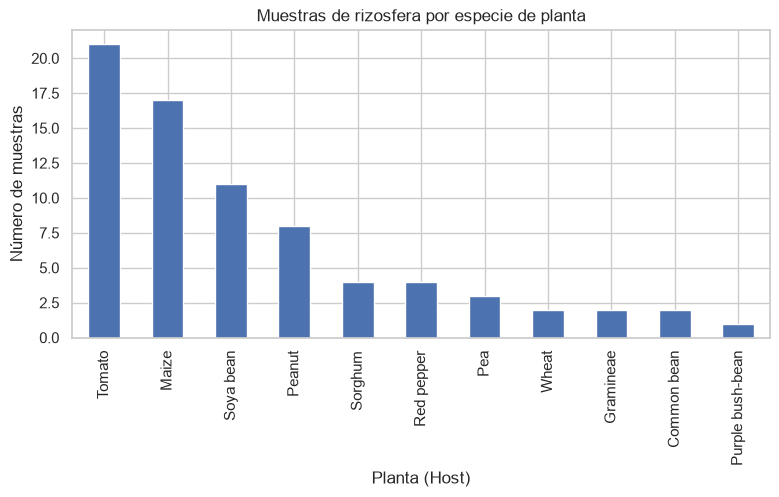

In [9]:
#| label: l4-distribucion-muestras-por-planta
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
# Propósito: visualizar cuántas muestras pertenecen a cada especie vegetal.
host_count = metadata_df['host_name'].value_counts()
plt.subplots(figsize=(9, 4))
host_count.plot(kind='bar', title='Muestras de rizosfera por especie de planta', xlabel='Planta (Host)', ylabel='Número de muestras')

## 1.2 selección de tomate y evaluación del tamaño de muestra

**Antes de comparar países**, revisamos su representación. Con pocos replicados por país, las correlaciones entre géneros son especialmente inestables. Las muestras sin país conocido se excluyen del análisis geográfico.

In [10]:
#| label: l4-distribucion-muestras-tomate-por-pais
#| code-fold: true
#| code-summary: "Ver el código"
# Propósito: seleccionar tomate y comprobar cuántas muestras quedan disponibles por país.
# Se excluyen muestras sin país y países pequeños se señalan porque sus correlaciones serán inestables.
host_value = "Tomato"
tomato_meta = metadata_df.loc[
    metadata_df["host_name"].eq(host_value) & metadata_df["country"].notna()
].copy().sort_values("country")
tomato_counts = counts_df.loc[:, tomato_meta.index]
nonempty = tomato_counts.sum(axis=0) > 0
tomato_counts = tomato_counts.loc[:, nonempty]
tomato_meta = tomato_meta.loc[tomato_counts.columns]
if tomato_counts.shape[1] < 2:
    raise ValueError("Se necesitan al menos dos muestras de tomate con conteos y país")
country_sizes = tomato_meta["country"].value_counts().sort_index()
print("Muestras de tomate por país:")
display(country_sizes.to_frame("n_muestras"))
if (country_sizes < 5).any():
    print("Advertencia: algunos países tienen menos de 5 muestras; interpretar con cautela.")


Muestras de tomate por país:


,n_muestras
country,
China,5
Mexico,5
Netherlands,6
South Africa,5


# 2. Exploración de abundancias taxonómicas


Para comparar perfiles de composición, normalizamos **cada muestra por separado**: 

$$\text{abundancia relativa} = \frac{\text{conteo del taxón}}{\text{suma de conteos de esa muestra}}.$$


Agrupamos características con la misma etiqueta de género; las etiquetas ausentes se conservan como `Sin asignar`. En estas gráficas, `Otros géneros` representa la abundancia que no está entre los 10 principales.

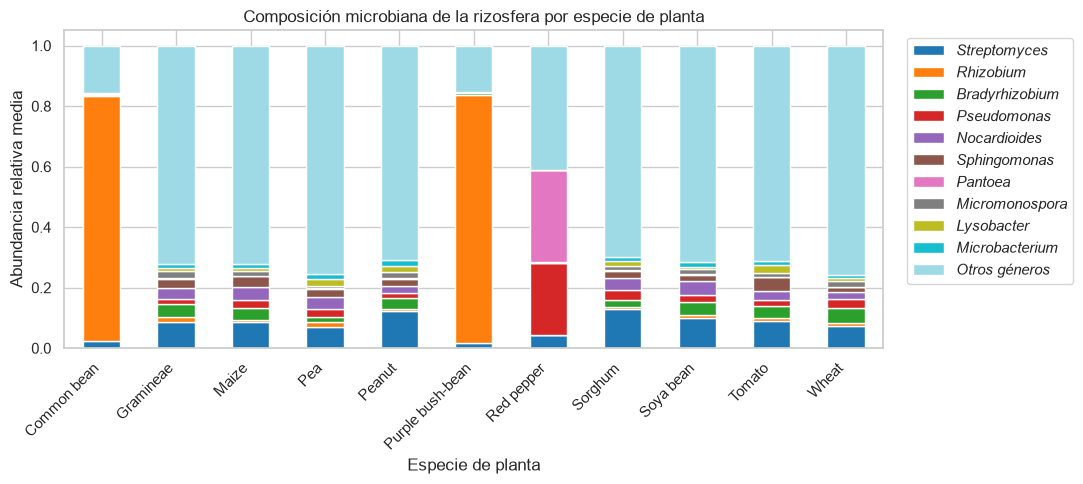

In [11]:
#| label: l4-abundancias-relativas-por-genero-tomate
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
# Propósito: agrupar conteos por género, normalizar cada muestra y comparar perfiles entre plantas.
# "Otros taxones y sin asignar" reúne la abundancia que queda fuera de los 10 géneros principales.
# 1. Primero limpiamos las etiquetas de género

def clean_genus(x):
    if pd.isna(x) or str(x).strip().lower() in ("", "none", "nan"):
        return "Sin asignar"
    return str(x).strip()


# 2. Obtener las etiquetas taxonómicas correspondientes a cada fila de la matriz de conteos
genus_labels = taxonomy_df["genus"].reindex(counts_df.index).map(clean_genus)

# 3. Agrupamos los conteos por género: sumar los conteos de los taxones que pertenecen al mismo género
genus_counts = counts_df.groupby(genus_labels, sort=False).sum()

# 4. Calculamos abundancias relativas por muestra
genus_rel = genus_counts.div(genus_counts.sum(axis=0).replace(0, np.nan), axis=1)

# 5. Identificamos los 10 géneros más abundantes: calcular abundancia relativa promedio entre muestras y excluir observaciones sin género asignado
top10_global = genus_rel.drop(index="Sin asignar", errors="ignore").mean(axis=1).nlargest(10).index.tolist()

# 6. Calculamos abundancias promedio por especie de planta
rel_by_host = genus_rel.T.join(metadata_df[["host_name"]]).groupby("host_name").mean().T

# 7. Preparamos los datos para la gráfica
host_plot = rel_by_host.reindex(top10_global).T.copy()
host_plot["Otros géneros"] = (1 - host_plot.sum(axis=1)).clip(lower=0)

# 8. Realizamos el plot
ax = host_plot.plot.bar(stacked=True, figsize=(11, 5), colormap="tab20")

ax.set(xlabel="Especie de planta",
       ylabel="Abundancia relativa media",
       title="Composición microbiana de la rizosfera por especie de planta"
)

# Los géneros van en cursiva, manipulamos la leyenda para eso
# Obtener los elementos de la leyenda
handles, labels = ax.get_legend_handles_labels()

# Crear la leyenda
legend = ax.legend(handles, labels, bbox_to_anchor=(1.02, 1), loc="upper left")

# Poner en cursivas los nombres de los géneros
for text in legend.get_texts():
    if text.get_text() != "Otros taxones y sin asignar":
        text.set_fontstyle("italic")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 2.1. Perfiles de las muestras de tomate por país

La gráfica siguiente muestra **cada muestra individual**. Los 10 géneros se eligen globalmente entre las muestras de tomate para mantener categorías comparables.

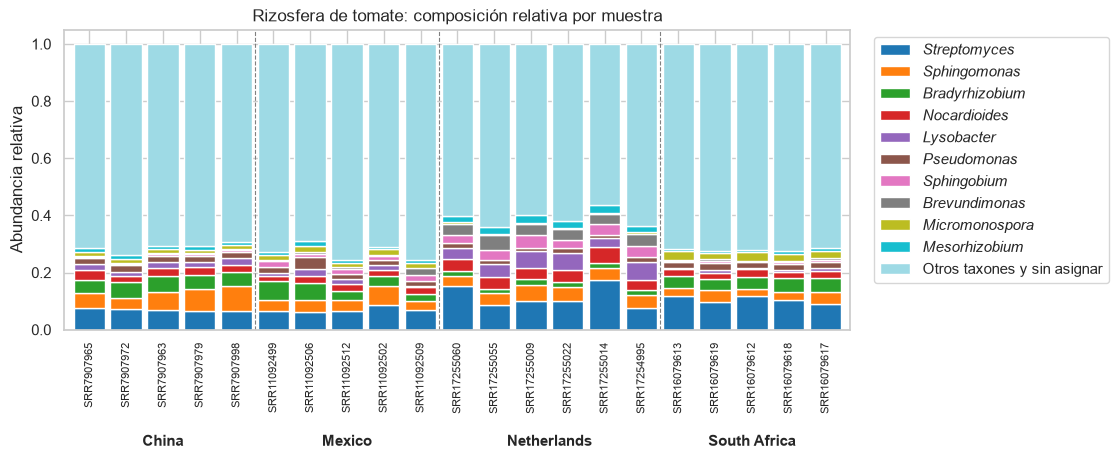

In [12]:
#| label: l4-top10-generos-tomate
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
# Propósito: mostrar la composición de los 10 géneros más abundantes en cada muestra de tomate.
# Las muestras se ordenan por país para facilitar la comparación visual.
# 1. Seleccionar las muestras de tomate
tomato_genus_rel = genus_rel.loc[:, tomato_meta.index]

# 2. Seleccionar los 10 géneros más abundantes (excluyendo los no asignados)
top10_tomato = tomato_genus_rel.drop(index="Sin asignar", errors="ignore").mean(axis=1).nlargest(10).index.tolist()

# 3. Preparar los datos para la gráfica
plot_samples = tomato_genus_rel.reindex(top10_tomato).T.copy()

plot_samples["Otros taxones y sin asignar"] = (1 - plot_samples.sum(axis=1)).clip(lower=0)

# 4. Agregar el país y ordenar las muestras
plot_samples["country"] = tomato_meta.loc[plot_samples.index, "country"]

plot_samples = plot_samples.sort_values("country")

# Guardar los países antes de graficar
countries = plot_samples.pop("country")

# 5. Crear la gráfica
fig, ax = plt.subplots(figsize=(max(12, 0.5 * len(plot_samples)), 6))

plot_samples.plot.bar(stacked=True, ax=ax, colormap="tab20", width=0.85)

ax.set(title="Rizosfera de tomate: composición relativa por muestra",
       xlabel="",
       ylabel="Abundancia relativa"
)

# 6. Mostrar los identificadores de las muestras
ax.set_xticklabels(plot_samples.index, rotation=90, fontsize=8)

# 7. Agregar separadores y nombres de países
for country in countries.unique():

    positions = np.where(countries.values == country)[0]

    start = positions[0]
    end = positions[-1]
    center = (start + end) / 2

    # Nombre del país debajo de las muestras
    ax.text(center, -0.35, str(country), ha="center", va="top", fontsize=11, fontweight="bold", transform=ax.get_xaxis_transform())

    # Separador entre países
    if end < len(plot_samples) - 1:
        ax.axvline(end + 0.5, color="gray", linestyle="--", linewidth=0.8)

# 8. Leyenda con géneros en cursivas
handles, labels = ax.get_legend_handles_labels()

legend = ax.legend(handles, labels, bbox_to_anchor=(1.02, 1), loc="upper left")

for text in legend.get_texts():
    if text.get_text() != "Otros taxones y sin asignar":
        text.set_fontstyle("italic")

# 9. Ajustar los márgenes
plt.subplots_adjust(bottom=0.38, right=0.78)

plt.show()

## 3. Red de similitud entre muestras mediante Bray-Curtis


La disimilitud de Bray-Curtis compara la composición de dos comunidades: 0 indica perfiles idénticos y 1 perfiles completamente diferentes.


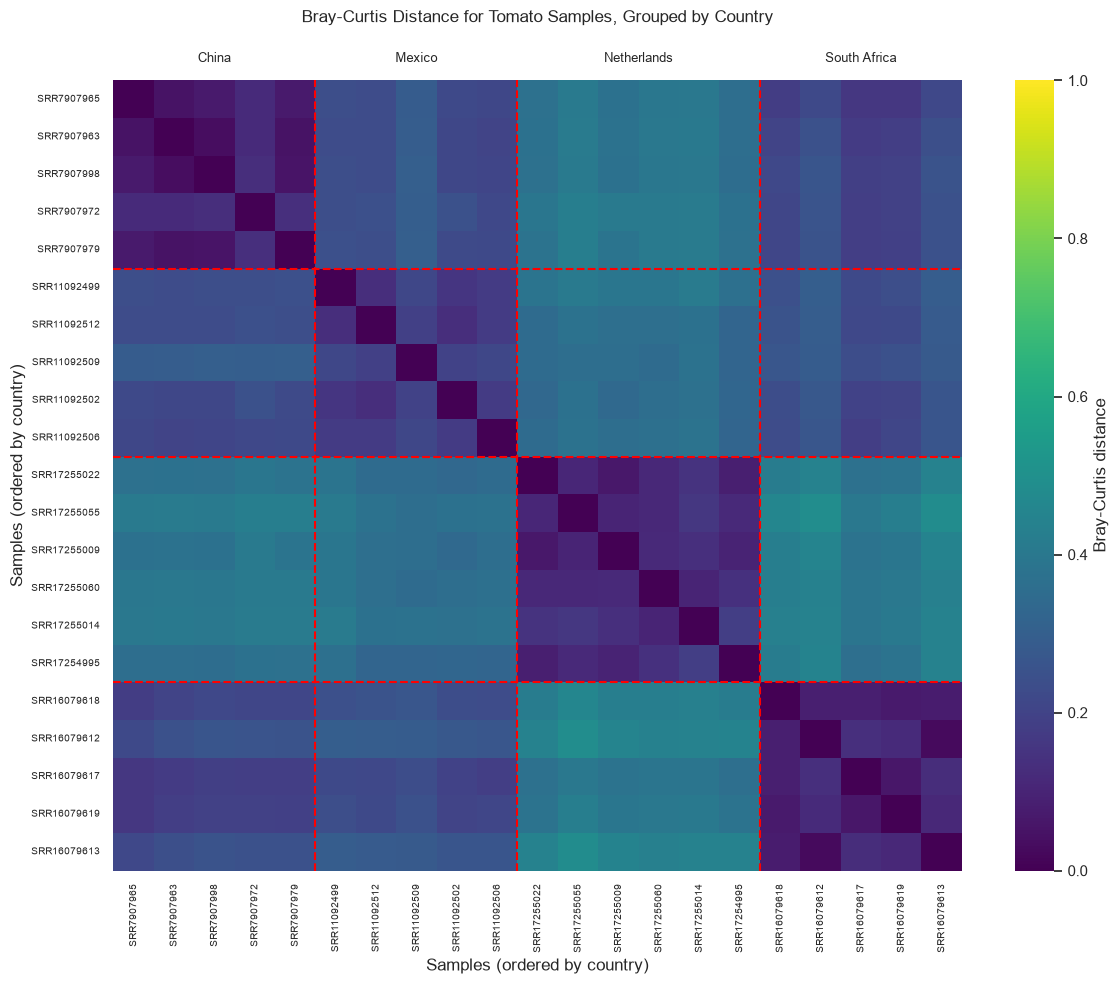

Samples included: 21
country
China           5
Mexico          5
Netherlands     6
South Africa    5
dtype: int64
Matrix shape: (21, 21)
Saved to: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Distancia_Bray-curtis/Heatmap/tomato_samples_by_country_braycurtis.jpg


In [13]:
#| label: l4-bray-curtis-tomate
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
# Propósito: calcular y visualizar la matriz de disimilitud Bray-Curtis entre muestras de tomate.
# La normalización por muestra es necesaria para comparar perfiles composicionales.
host_value = 'Tomato'

# Normalizar por muestra antes de calcular Bray-Curtis
relative_counts_df = counts_df.div(
    counts_df.sum(axis=0).replace(0, np.nan), axis=1
)

# Alineamos la metadata de las muestras de BIOM, luego mantenemos las muestras de tomate con un país conocido
tomato_meta = metadata_df.reindex(relative_counts_df.columns)
tomato_meta = tomato_meta.loc[
    tomato_meta['host_name'].eq(host_value) & tomato_meta['country'].notna()
].sort_values(['country'], kind='stable')

tomato_samples = tomato_meta.index.tolist()
if len(tomato_samples) < 2:
    raise ValueError(f'Need at least two {host_value} samples with country metadata.')

# Calculamos la matriz de distancia de Bray-Curtis para las muestras de tomate y creamos un DataFrame para facilitar la visualización
braycurtis_tomato = pairwise_distances(
    relative_counts_df.loc[:, tomato_samples].T,
    metric='braycurtis'
)
braycurtis_tomato_by_country = pd.DataFrame(
    braycurtis_tomato,
    index=tomato_samples,
    columns=tomato_samples
)

# Creamos un heatmap de la matriz de distancia de Bray-Curtis para las muestras de tomate, agrupadas por país
fig, ax = plt.subplots(
    figsize=(max(12, 0.22 * len(tomato_samples) + 5), max(10, 0.18 * len(tomato_samples) + 5))
)
sns.heatmap(
    braycurtis_tomato_by_country,
    cmap='viridis',
    vmin=0,
    vmax=1,
    xticklabels=tomato_samples,
    yticklabels=tomato_samples,
    cbar_kws={'label': 'Bray-Curtis distance'},
    ax=ax
)

# Agregamos líneas de separación y etiquetas de país en el heatmap
country_groups = tomato_meta.groupby('country', sort=False).size()
boundary = 0
for country, sample_count in country_groups.items():
    if boundary > 0:
        ax.axvline(boundary, color='red', linestyle='--', linewidth=1.5)
        ax.axhline(boundary, color='red', linestyle='--', linewidth=1.5)
    ax.text(
        boundary + sample_count / 2,
        1.02,
        country,
        ha='center',
        va='bottom',
        fontsize=9,
        transform=ax.get_xaxis_transform()
    )
    boundary += sample_count

ax.set_title(f'Bray-Curtis Distance for {host_value} Samples, Grouped by Country', pad=42)
ax.set_xlabel('Samples (ordered by country)')
ax.set_ylabel('Samples (ordered by country)')
ax.tick_params(axis='x', labelrotation=90, labelsize=7)
ax.tick_params(axis='y', labelsize=7)
fig.tight_layout()

heatmap_dir = os.path.join(workdir, 'Distancia_Bray-curtis', 'Heatmap')
os.makedirs(heatmap_dir, exist_ok=True)
save_path = os.path.join(heatmap_dir, 'tomato_samples_by_country_braycurtis.jpg')
fig.savefig(save_path, bbox_inches='tight', dpi=150)
plt.show()
plt.close(fig)

print(f'Samples included: {len(tomato_samples)}')
print(country_groups)
print(f'Matrix shape: {braycurtis_tomato_by_country.shape}')
print(f'Saved to: {save_path}')

# 3. Red de similitud

## 4. Construcción de la red de similitud

Cada nodo es una muestra. Una arista conecta dos muestras cuando su disimilitud es menor o igual al umbral elegido.


Cada nodo es una **muestra**. Se añade una arista si su disimilitud es menor o igual a $\varepsilon$. El umbral de 0.2 se utiliza **como ejemplo visual**, no como resultado óptimo ni como evidencia de agrupación. La posición de los nodos se calcula a partir de la red, **sin imponer centros geográficos**. Los colores solo se añaden al final.

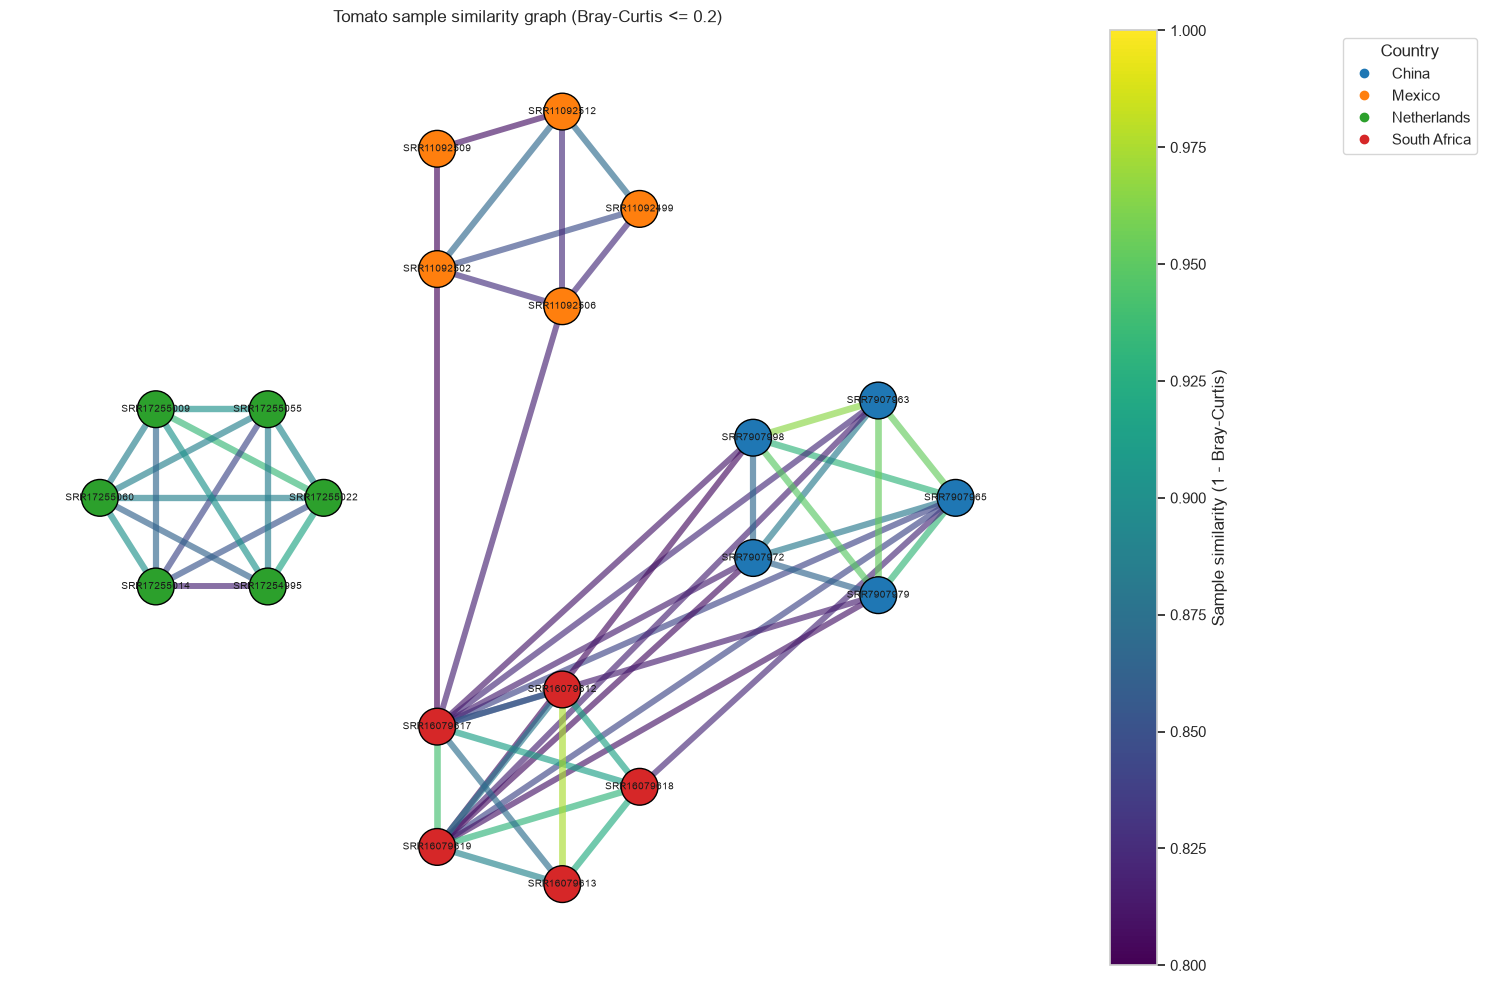

Nodes: 21
Edges: 56
Countries: 4
Saved to: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Grafos/Tomato/tomato_braycurtis_similarity_graph.png


In [14]:
#| label: l4-red-similitud
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
# Propósito: construir una red de muestras conectando pares con Bray-Curtis menor o igual al umbral.
# El umbral de 0.2 es ilustrativo; cambiarlo modifica nodos conectados, componentes y densidad.
max_braycurtis_distance = 0.2

sample_meta = metadata_df.reindex(braycurtis_tomato_by_country.index)
sample_meta = sample_meta.loc[sample_meta['country'].notna()]
sample_ids = sample_meta.index.intersection(braycurtis_tomato_by_country.index, sort=False)
distance_df = braycurtis_tomato_by_country.loc[sample_ids, sample_ids]
sample_meta = sample_meta.loc[sample_ids]

country_names = sorted(sample_meta['country'].unique())
country_palette = {
    country: plt.cm.tab10(i % 10)
    for i, country in enumerate(country_names)
}

tomato_sample_graph = nx.Graph(host_name='Tomato')
for sample_id, row in sample_meta.iterrows():
    tomato_sample_graph.add_node(sample_id, country=row['country'])

for sample_a, sample_b in combinations(sample_ids, 2):
    distance = distance_df.loc[sample_a, sample_b]
    if distance <= max_braycurtis_distance:
        tomato_sample_graph.add_edge(
            sample_a,
            sample_b,
            braycurtis_distance=distance,
            similarity=1 - distance
        )

country_centers = {
    country: (
        2.4 * np.cos(2 * np.pi * i / len(country_names)),
        2.4 * np.sin(2 * np.pi * i / len(country_names))
    )
    for i, country in enumerate(country_names)
}
pos = {}
for country in country_names:
    country_samples = [
        sample_id for sample_id in tomato_sample_graph.nodes
        if tomato_sample_graph.nodes[sample_id]['country'] == country
    ]
    local_pos = nx.circular_layout(country_samples, scale=0.85)
    center_x, center_y = country_centers[country]
    for sample_id, (x, y) in local_pos.items():
        pos[sample_id] = (center_x + x, center_y + y)

fig, ax = plt.subplots(figsize=(15, 10))
edge_similarities = [
    tomato_sample_graph[u][v]['similarity']
    for u, v in tomato_sample_graph.edges
]
if edge_similarities:
    nx.draw_networkx_edges(
        tomato_sample_graph,
        pos,
        ax=ax,
        width=[1 + 4 * value for value in edge_similarities],
        edge_color=edge_similarities,
        edge_cmap=plt.cm.viridis,
        edge_vmin=1 - max_braycurtis_distance,
        edge_vmax=1,
        alpha=0.65
    )
nx.draw_networkx_nodes(
    tomato_sample_graph,
    pos,
    ax=ax,
    node_size=700,
    node_color=[
        country_palette[tomato_sample_graph.nodes[node]['country']]
        for node in tomato_sample_graph.nodes
    ],
    edgecolors='black'
)
nx.draw_networkx_labels(
    tomato_sample_graph,
    pos,
    ax=ax,
    labels={node: node for node in tomato_sample_graph.nodes},
    font_size=7
)
ax.legend(
    handles=[
        plt.Line2D([], [], marker='o', linestyle='', color=country_palette[country], label=country)
        for country in country_names
    ],
    title='Country', loc='upper left', bbox_to_anchor=(1.28, 1.0)
)
if edge_similarities:
    edge_mapper = plt.cm.ScalarMappable(
        norm=plt.Normalize(vmin=1 - max_braycurtis_distance, vmax=1),
        cmap=plt.cm.viridis
    )
    fig.colorbar(edge_mapper, ax=ax, label='Sample similarity (1 - Bray-Curtis)')
ax.set_title(
    f'Tomato sample similarity graph (Bray-Curtis <= {max_braycurtis_distance})'
)
ax.axis('off')
fig.tight_layout()

graph_dir = os.path.join(workdir, 'Grafos', 'Tomato')
os.makedirs(graph_dir, exist_ok=True)
save_path = os.path.join(graph_dir, 'tomato_braycurtis_similarity_graph.png')
fig.savefig(save_path, bbox_inches='tight', dpi=150)
plt.show()
plt.close(fig)

print(f'Nodes: {tomato_sample_graph.number_of_nodes()}')
print(f'Edges: {tomato_sample_graph.number_of_edges()}')
print(f'Countries: {len(country_names)}')
print(f'Saved to: {save_path}')

::: {.callout-tip}
### Solución del instructor — Ejercicio 1: umbrales por cuartiles
Calculamos los cuartiles de las disimilitudes distintas de cero y construimos una red para cada umbral. Se comparan aristas, componentes y densidad.
:::


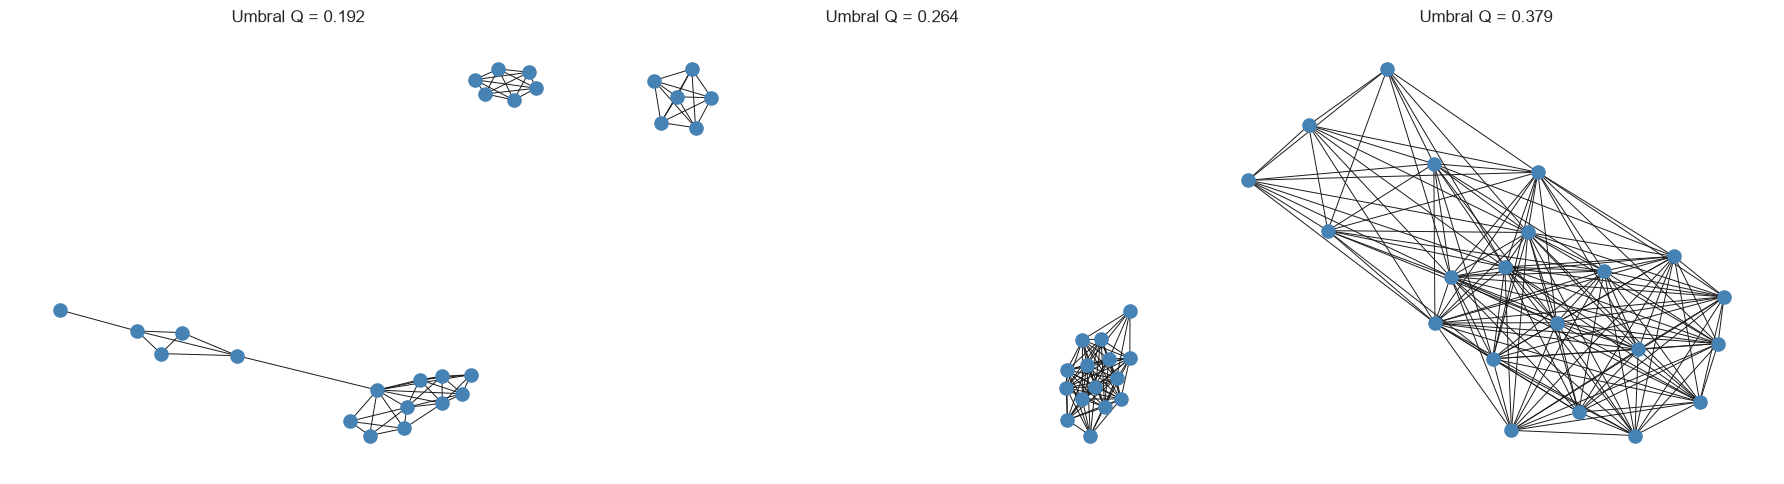

,threshold,edges,components,density
0,0.191956,53,2,0.252381
1,0.263869,105,2,0.500000
2,0.379133,157,1,0.747619


In [15]:
# Propósito: resolver el Ejercicio 1 construyendo redes con los cuartiles de las disimilitudes.
# La tabla final resume cómo cambian aristas, componentes y densidad al aumentar el umbral.
distance_values = braycurtis_tomato_by_country.to_numpy()
upper_triangle = distance_values[np.triu_indices_from(distance_values, k=1)]
thresholds = np.unique(np.quantile(upper_triangle, [0.25, 0.5, 0.75]))
threshold_summary = []

fig, axes = plt.subplots(1, len(thresholds), figsize=(6 * len(thresholds), 5))
axes = np.atleast_1d(axes)
base_nodes = braycurtis_tomato_by_country.index

for ax, threshold in zip(axes, thresholds):
    graph = nx.Graph()
    graph.add_nodes_from(base_nodes)
    for sample_a, sample_b in combinations(base_nodes, 2):
        distance = braycurtis_tomato_by_country.loc[sample_a, sample_b]
        if distance <= threshold:
            graph.add_edge(sample_a, sample_b)
    positions = nx.spring_layout(graph, seed=4)
    nx.draw(
        graph, positions, ax=ax, node_size=90, width=0.7,
        node_color="steelblue", with_labels=False
    )
    ax.set_title(f"Umbral Q = {threshold:.3f}")
    threshold_summary.append({
        "threshold": threshold,
        "edges": graph.number_of_edges(),
        "components": nx.number_connected_components(graph),
        "density": nx.density(graph),
    })

plt.tight_layout()
plt.show()
pd.DataFrame(threshold_summary)


## 5. Homología persistente con complejo de Vietoris-Rips


Los complejos simpliciales permiten estudiar componentes conectadas, ciclos y estructuras de dimensiones superiores. En vez de fijar un único umbral, la homología persistente registra cuándo aparecen y desaparecen al aumentar la distancia de filtración.


Un complejo de Vietoris-Rips incluye un simplex cuando todos sus vértices están mutuamente separados por una distancia menor o igual al parámetro de filtración. El diagrama de persistencia resume la vida de cada componente o ciclo.


Calculamos el diagrama de persistencia de la matriz de Bray-Curtis entre muestras de tomate.


In [16]:
#| label: l4-TDA-create_complex
#| code-fold: true
#| code-summary: "Ver el código"
# Propósito: encapsular el cálculo y la visualización de homología persistente con Vietoris-Rips.
# La función guarda el diagrama y el código de barras, y devuelve los datos usados en comparaciones posteriores.
from IPython.display import display

def create_complex(distance_matrix, label=""):
    rips_complex = gd.RipsComplex(distance_matrix=np.asarray(distance_matrix))
    simplex_tree = rips_complex.create_simplex_tree(max_dimension=3)
    persistence = simplex_tree.persistence()

    output_dir = Path(workdir) / "Diagramas_Persistencia"
    output_dir.mkdir(parents=True, exist_ok=True)
    file_prefix = (
        re.sub(r"[^A-Za-z0-9_-]+", "_", str(label)).strip("_") + "_"
        if label else ""
    )
    title_prefix = f"{label} - " if label else ""

    diagram_ax = gd.plot_persistence_diagram(persistence, legend=True)
    diagram_ax.set_title(f"{title_prefix}Persistence Diagram")
    diagram_fig = diagram_ax.get_figure()
    diagram_fig.tight_layout()
    diagram_path = output_dir / f"{file_prefix}persistence_diagram.png"
    diagram_fig.savefig(diagram_path, bbox_inches="tight", dpi=150)
    display(diagram_fig)
    plt.close(diagram_fig)

    barcode_ax = gd.plot_persistence_barcode(persistence)
    barcode_ax.set_title(f"{title_prefix}Persistence Barcode")
    barcode_fig = barcode_ax.get_figure()
    barcode_fig.tight_layout()
    barcode_path = output_dir / f"{file_prefix}persistence_barcode.png"
    barcode_fig.savefig(barcode_path, bbox_inches="tight", dpi=150)
    display(barcode_fig)
    plt.close(barcode_fig)

    print(f"Diagrama guardado en: {diagram_path}")
    print(f"Código de barras guardado en: {barcode_path}")
    return persistence, simplex_tree


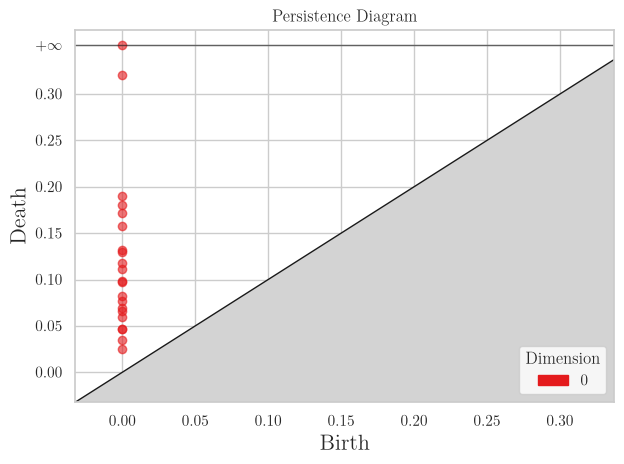

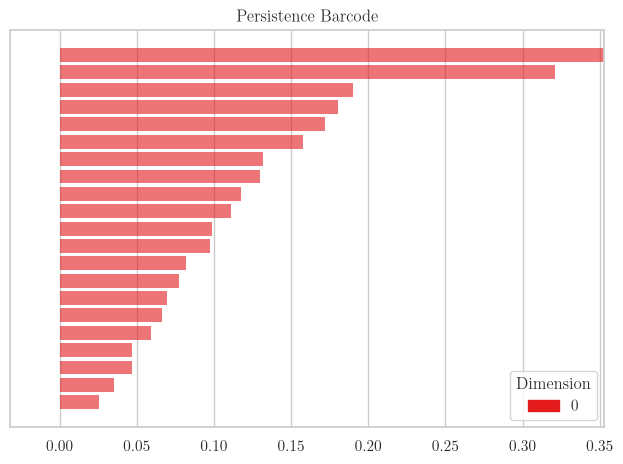

Diagrama guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/persistence_diagram.png
Código de barras guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/persistence_barcode.png


([(0, (0.0, inf)),
  (0, (0.0, 0.3210261985686163)),
  (0, (0.0, 0.1904646449177838)),
  (0, (0.0, 0.18066314633117003)),
  (0, (0.0, 0.17203338839620713)),
  (0, (0.0, 0.15760748976098923)),
  (0, (0.0, 0.13209421346709158)),
  (0, (0.0, 0.12984991513973504)),
  (0, (0.0, 0.11783924781938757)),
  (0, (0.0, 0.11140836851275454)),
  (0, (0.0, 0.09848368430655458)),
  (0, (0.0, 0.0976875364324084)),
  (0, (0.0, 0.08212163324936156)),
  (0, (0.0, 0.07724487418071604)),
  (0, (0.0, 0.0694150440415104)),
  (0, (0.0, 0.06636946785038148)),
  (0, (0.0, 0.05941708833491835)),
  (0, (0.0, 0.047029452153165695)),
  (0, (0.0, 0.046938519385192695)),
  (0, (0.0, 0.03507634163222924)),
  (0, (0.0, 0.025433010398053915))],
 <gudhi.simplex_tree.SimplexTree at 0x11749e5d0>)

In [17]:
#| label: l4-TDA-braycurtis-tomato
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
# Propósito: aplicar la función de homología persistente a la red de muestras de tomate.
create_complex(braycurtis_tomato)

Una estructura con pocos ciclos persistentes es compatible con una organización casi arbórea, pero no demuestra mutualismo, jerarquía ecológica ni causalidad entre microorganismos.


## 6. Redes exploratorias de asociaciones entre géneros


Ahora los nodos son géneros. Las aristas representan asociaciones monotónicas de abundancias dentro de muestras de tomate de un mismo país. Spearman no demuestra una interacción ecológica y los datos composicionales pueden inducir correlaciones espurias.


In [18]:
# Propósito: definir países elegibles y un conjunto común de géneros variables.
# Un mismo conjunto de nodos hace comparables las redes; un género constante se excluye porque su Spearman es indefinida.
min_samples_corr = 5
selected_top_n = 10

eligible_countries = country_sizes[country_sizes >= min_samples_corr].index.tolist()
if len(eligible_countries) < 2:
    raise ValueError("Se requieren al menos dos países con suficientes muestras.")

# Elegimos los mismos géneros en todos los países. Deben variar dentro de cada país.
candidate_genera = (
    tomato_genus_rel.drop(index="Sin asignar", errors="ignore")
    .mean(axis=1)
    .nlargest(30)
    .index.tolist()
)
selected_genera = []
for genus in candidate_genera:
    variable_everywhere = True
    for country in eligible_countries:
        samples = tomato_meta.index[tomato_meta["country"].eq(country)]
        values = tomato_genus_rel.loc[genus, samples]
        if values.nunique(dropna=True) <= 1:
            variable_everywhere = False
            break
    if variable_everywhere:
        selected_genera.append(genus)
    if len(selected_genera) == selected_top_n:
        break

if len(selected_genera) < 2:
    raise ValueError("No hay suficientes géneros variables en todos los países elegibles.")

print("Países elegibles:", eligible_countries)
print("Géneros comunes:", selected_genera)


Países elegibles: ['China', 'Mexico', 'Netherlands', 'South Africa']
Géneros comunes: ['Streptomyces', 'Sphingomonas', 'Bradyrhizobium', 'Nocardioides', 'Lysobacter', 'Pseudomonas', 'Sphingobium', 'Brevundimonas', 'Micromonospora', 'Mesorhizobium']


## 7. Correlaciones y transformación a disimilitudes


Calculamos Spearman entre géneros y transformamos la correlación en tres disimilitudes exploratorias: absoluta, positiva y negativa.


In [19]:
#| label: l4-spearman-corr-matrix
#| code-fold: true
#| code-summary: "Ver el código"
# Propósito: calcular correlación de Spearman y valores p entre géneros de un país.
# Los géneros constantes se eliminan y nunca se reemplazan sus correlaciones indefinidas por cero.
def spearman_corr_matrix(working_directory: str, suffix: str, genus_df_filtered: pd.DataFrame):
    os.makedirs(working_directory, exist_ok=True)

    rel_abund = genus_df_filtered.div(genus_df_filtered.sum(axis=0), axis=1)
    rel_abund = rel_abund.replace([np.inf, -np.inf], np.nan)
    rel_abund = rel_abund.loc[rel_abund.nunique(axis=1, dropna=True) > 1]

    if rel_abund.shape[0] < 2:
        raise ValueError('At least two variable genera are needed to calculate correlations.')

    result = stats.spearmanr(rel_abund.T, axis=0, nan_policy='omit')
    genera = rel_abund.index
    corr_values = np.array(result.statistic, copy=True)
    pval_values = np.array(result.pvalue, copy=True)
    np.fill_diagonal(corr_values, 1.0)
    np.fill_diagonal(pval_values, 0.0)
    corr_matrix = pd.DataFrame(corr_values, index=genera, columns=genera)
    pval_matrix = pd.DataFrame(pval_values, index=genera, columns=genera)

    corr_matrix.to_csv(os.path.join(working_directory, f'corr_matrix_{suffix}.csv'))
    pval_matrix.to_csv(os.path.join(working_directory, f'pval_matrix_{suffix}.csv'))

    return corr_matrix, pval_matrix

In [20]:
#| label: l4-corr_to_distance
#| code-fold: true
#| code-summary: "Ver el código"
# Propósito: transformar Spearman en disimilitudes absoluta, positiva y negativa.
# Estas transformaciones sirven para filtraciones exploratorias; no son necesariamente distancias métricas.
def corr_to_distance(working_directory: str, suffix: str, corr_matrix: pd.DataFrame):
    os.makedirs(working_directory, exist_ok=True)
    corr_values = corr_matrix.to_numpy(dtype=float, copy=True)
    indices = corr_matrix.index
    columns = corr_matrix.columns

    abs_values = 1 - np.abs(corr_values)
    positive_values = np.clip(corr_values, 0, None)
    positive_distance_values = 1 - np.abs(positive_values)
    negative_values = np.clip(corr_values, None, 0)
    negative_distance_values = 1 - np.abs(negative_values)

    for values in (abs_values, positive_distance_values, negative_distance_values):
        np.fill_diagonal(values, 0.0)

    corr_matrix_abs = pd.DataFrame(abs_values, index=indices, columns=columns)
    corr_matrix_mas = pd.DataFrame(positive_distance_values, index=indices, columns=columns)
    corr_matrix_menos = pd.DataFrame(negative_distance_values, index=indices, columns=columns)

    corr_matrix_abs.to_csv(os.path.join(working_directory, f'corr_matrix_abs_{suffix}.csv'))
    corr_matrix_mas.to_csv(os.path.join(working_directory, f'corr_matrix_mas_{suffix}.csv'))
    corr_matrix_menos.to_csv(os.path.join(working_directory, f'corr_matrix_menos_{suffix}.csv'))

    print(f'Distance matrices saved to: {working_directory}/')
    return corr_matrix_abs, corr_matrix_mas, corr_matrix_menos

### Ejemplo principal: South Africa


In [21]:
# Propósito: preparar el ejemplo principal de South Africa con el conjunto común de géneros.
# Primero se agrupa por género y después se calculan correlaciones y disimilitudes.
country_name = "South Africa"
top_n_genera = len(selected_genera)
south_africa_samples = tomato_meta.loc[
    tomato_meta["country"].eq(country_name)
].index.intersection(counts_df.columns, sort=False)
if len(south_africa_samples) < min_samples_corr:
    raise ValueError(f"Se necesitan al menos {min_samples_corr} muestras para {country_name}.")

south_africa_genus_counts = (
    counts_df.loc[:, south_africa_samples]
    .groupby(taxonomy_df["genus"].map(lambda x: x if pd.notna(x) else "Sin asignar"))
    .sum()
    .reindex(selected_genera)
    .fillna(0)
)

corr_output_dir = Path(workdir) / "Corr_Spearman" / "South_Africa"
suffix = "tomato_south_africa"
corr_matrix_south_africa, pval_matrix_south_africa = spearman_corr_matrix(
    str(corr_output_dir), suffix, south_africa_genus_counts
)
(
    corr_matrix_abs_south_africa,
    corr_matrix_pos_south_africa,
    corr_matrix_neg_south_africa,
) = corr_to_distance(str(corr_output_dir), suffix, corr_matrix_south_africa)

print(f"País: {country_name}")
print(f"Muestras: {len(south_africa_samples)}")
print(f"Géneros comunes: {list(corr_matrix_south_africa.index)}")


Distance matrices saved to: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Corr_Spearman/South_Africa/
País: South Africa
Muestras: 5
Géneros comunes: ['Streptomyces', 'Sphingomonas', 'Bradyrhizobium', 'Nocardioides', 'Lysobacter', 'Pseudomonas', 'Sphingobium', 'Brevundimonas', 'Micromonospora', 'Mesorhizobium']


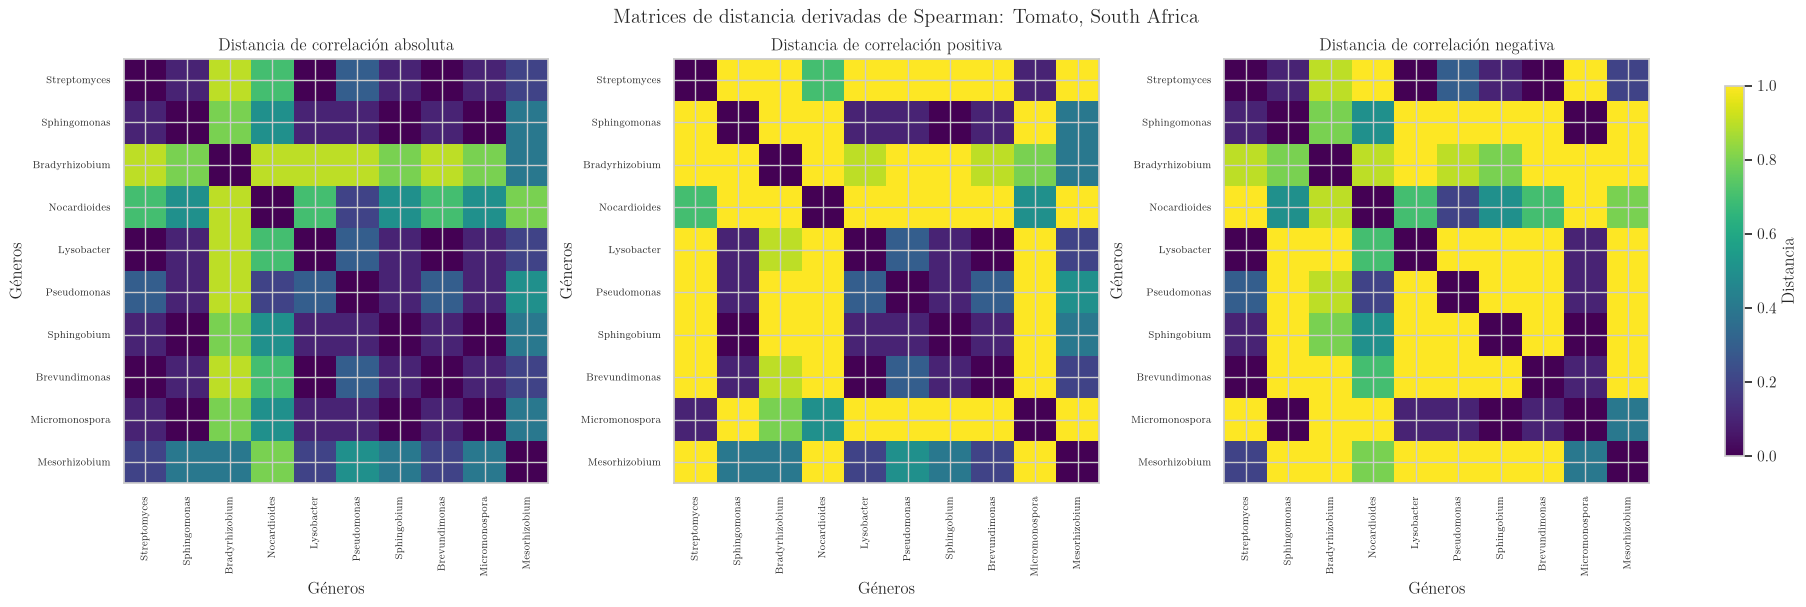

Dimensiones: (10, 10); guardado en /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Corr_Spearman/South_Africa/Heatmap/tomato_south_africa_correlation_distances.jpg


In [22]:
#| label: l4-plot-corr-distance-matrices-south-africa
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
# Propósito: comparar visualmente las tres matrices de disimilitud de South Africa.
distance_matrices = [
    ("Absoluta", corr_matrix_abs_south_africa),
    ("Positiva", corr_matrix_pos_south_africa),
    ("Negativa", corr_matrix_neg_south_africa),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
for ax, (title, matrix) in zip(axes, distance_matrices):
    image = ax.imshow(matrix.to_numpy(), cmap="viridis", vmin=0, vmax=1)
    ax.set_title(f"Distancia de correlación {title.lower()}")
    ax.set_xticks(range(len(matrix)), matrix.index, rotation=90, fontsize=7)
    ax.set_yticks(range(len(matrix)), matrix.index, fontsize=7)
    ax.set_xlabel("Géneros")
    ax.set_ylabel("Géneros")

fig.colorbar(image, ax=axes, label="Distancia", shrink=0.8)
fig.suptitle("Matrices de distancia derivadas de Spearman: Tomato, South Africa")
heatmap_dir = corr_output_dir / "Heatmap"
heatmap_dir.mkdir(parents=True, exist_ok=True)
save_path = heatmap_dir / "tomato_south_africa_correlation_distances.jpg"
fig.savefig(save_path, bbox_inches="tight", dpi=200)
plt.show()
plt.close(fig)
print(f"Dimensiones: {corr_matrix_abs_south_africa.shape}; guardado en {save_path}")


Distance matrices saved to: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Corr_Spearman/China/


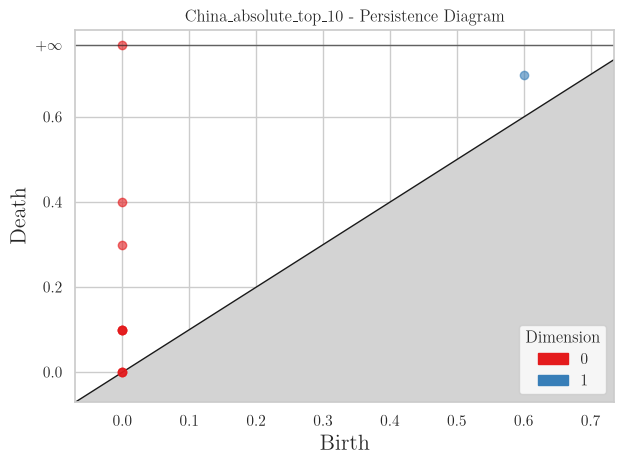

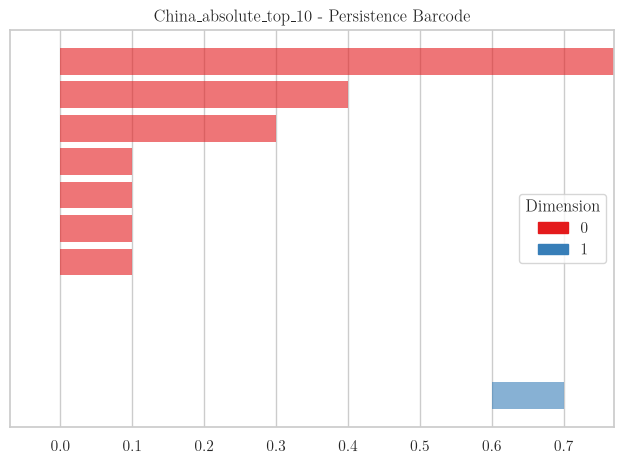

Diagrama guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/China_absolute_top_10_persistence_diagram.png
Código de barras guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/China_absolute_top_10_persistence_barcode.png


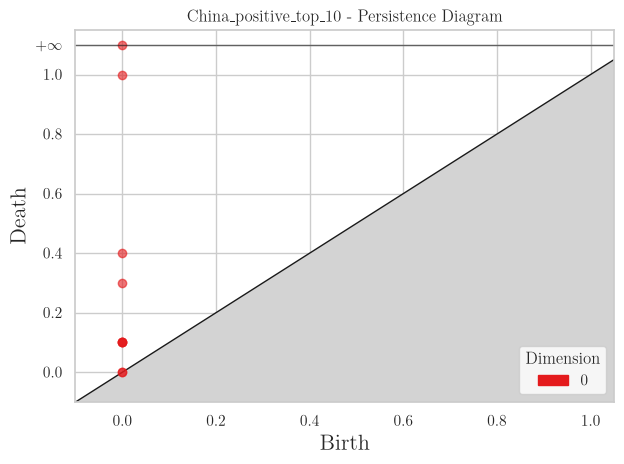

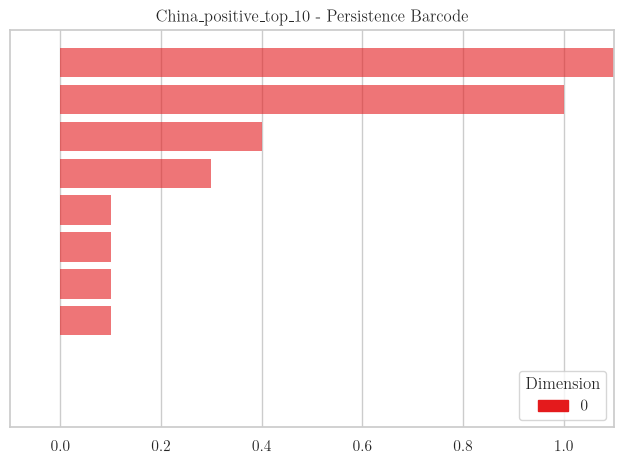

Diagrama guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/China_positive_top_10_persistence_diagram.png
Código de barras guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/China_positive_top_10_persistence_barcode.png


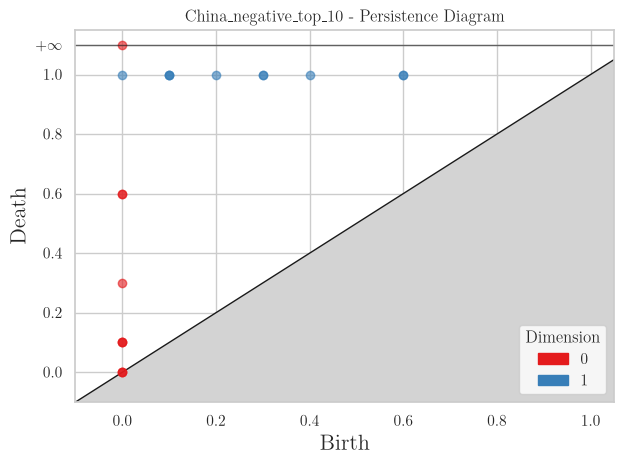

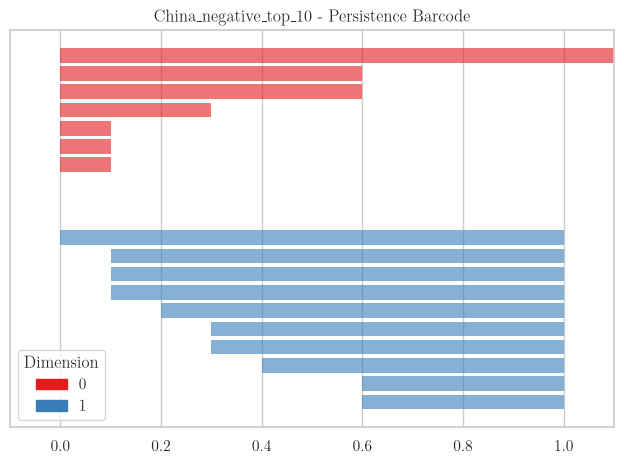

Diagrama guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/China_negative_top_10_persistence_diagram.png
Código de barras guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/China_negative_top_10_persistence_barcode.png
Distance matrices saved to: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Corr_Spearman/Mexico/


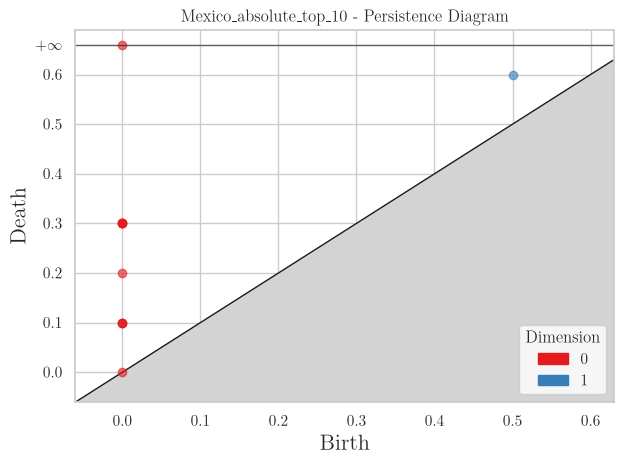

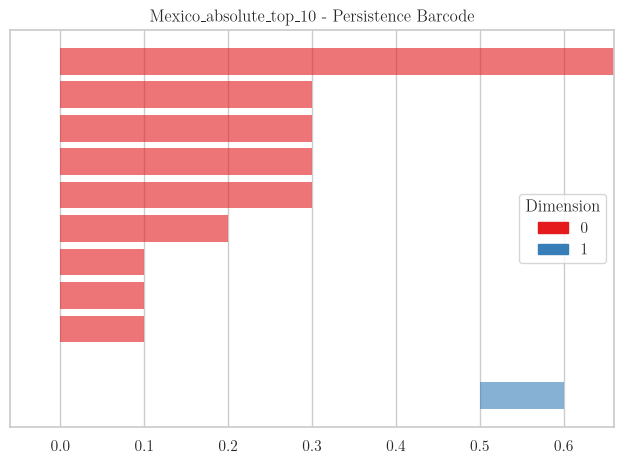

Diagrama guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/Mexico_absolute_top_10_persistence_diagram.png
Código de barras guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/Mexico_absolute_top_10_persistence_barcode.png


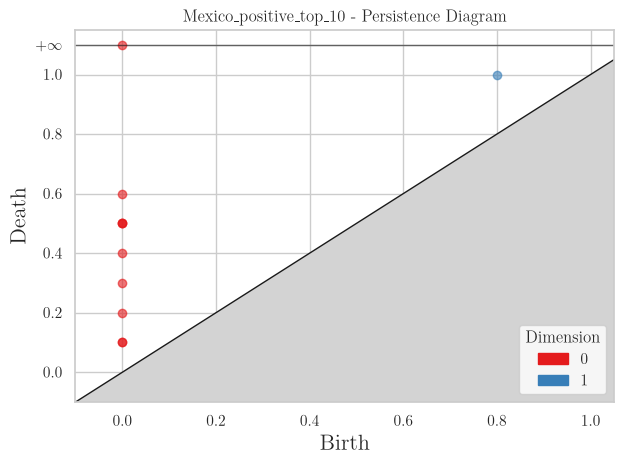

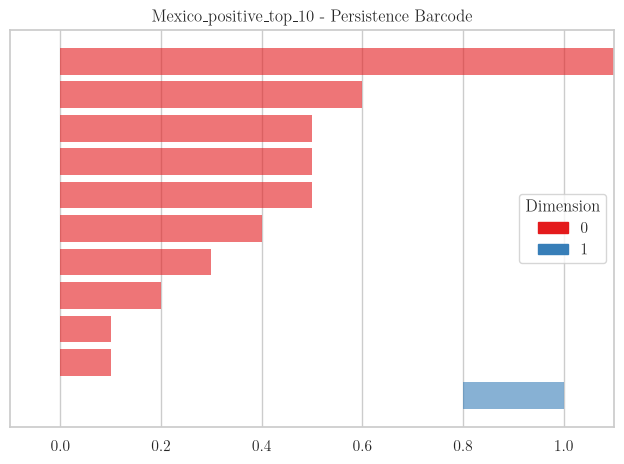

Diagrama guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/Mexico_positive_top_10_persistence_diagram.png
Código de barras guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/Mexico_positive_top_10_persistence_barcode.png


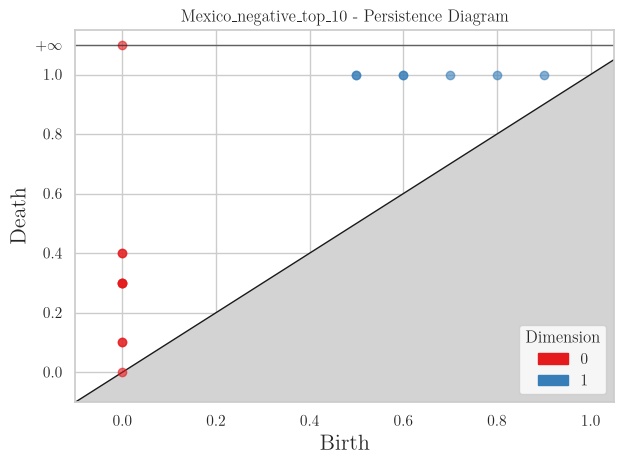

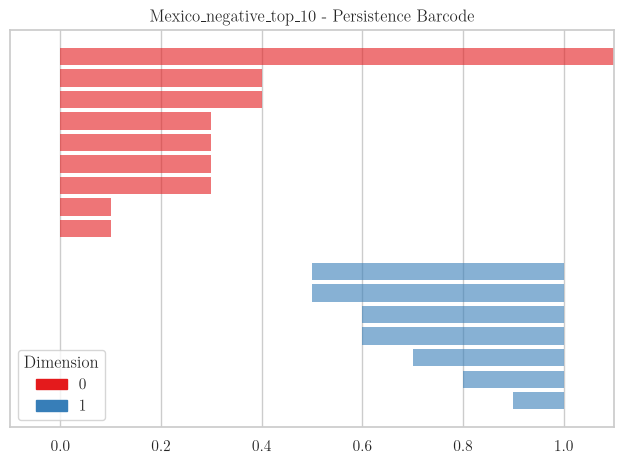

Diagrama guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/Mexico_negative_top_10_persistence_diagram.png
Código de barras guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/Mexico_negative_top_10_persistence_barcode.png
Distance matrices saved to: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Corr_Spearman/Netherlands/


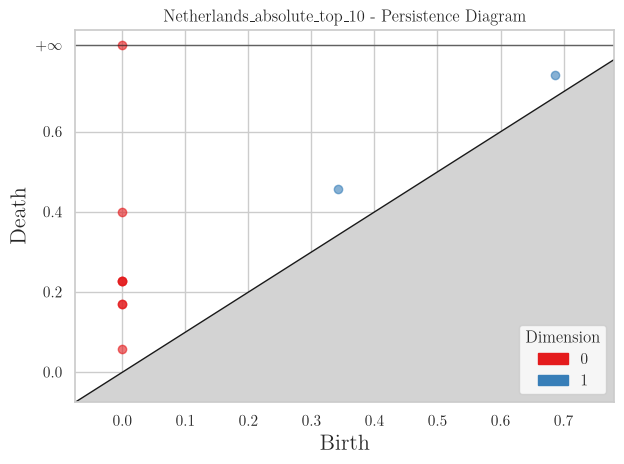

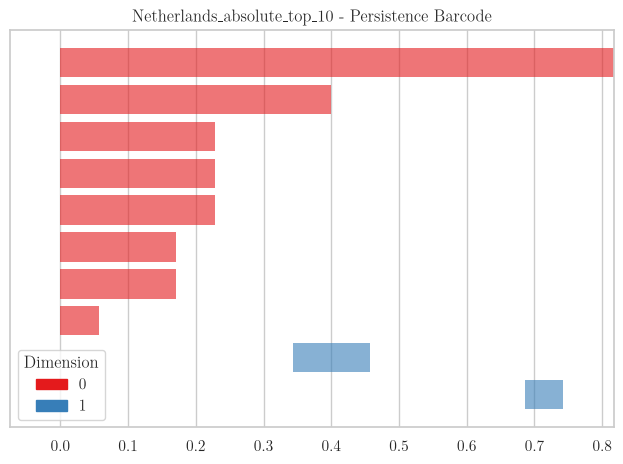

Diagrama guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/Netherlands_absolute_top_10_persistence_diagram.png
Código de barras guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/Netherlands_absolute_top_10_persistence_barcode.png


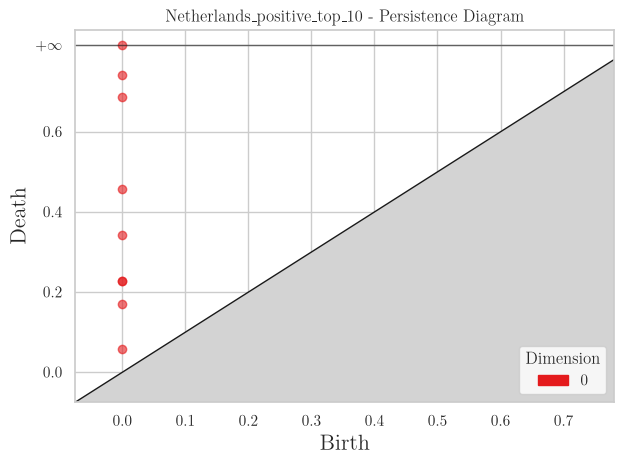

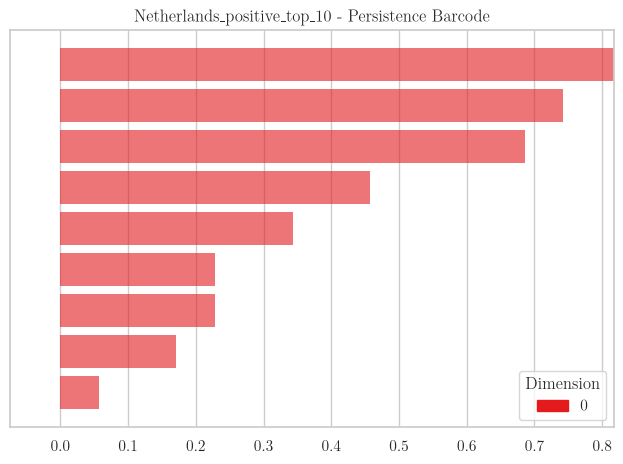

Diagrama guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/Netherlands_positive_top_10_persistence_diagram.png
Código de barras guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/Netherlands_positive_top_10_persistence_barcode.png


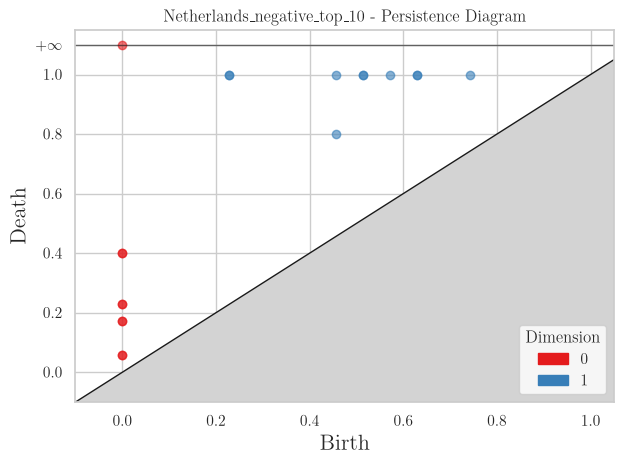

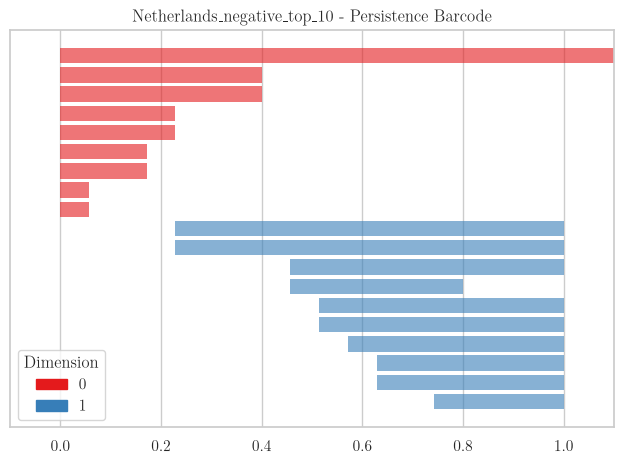

Diagrama guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/Netherlands_negative_top_10_persistence_diagram.png
Código de barras guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/Netherlands_negative_top_10_persistence_barcode.png
Países adicionales analizados: ['China', 'Mexico', 'Netherlands']


In [23]:
# Propósito: resolver la parte de análisis de los demás países para los ejercicios 2 y 3.
# Se repite exactamente el mismo procedimiento y se conserva la misma selección de géneros.
# Solución base para los ejercicios 2 y 3: analizar los demás países elegibles.
countries_to_process = [
    country for country in eligible_countries if country != "South Africa"
]
correlation_results_by_country = {}

for country_name in countries_to_process:
    country_meta = tomato_meta.loc[tomato_meta["country"].eq(country_name)]
    sample_ids = country_meta.index.intersection(counts_df.columns, sort=False)
    country_counts = counts_df.loc[:, sample_ids]
    genus_counts = (
        country_counts.groupby(
            taxonomy_df["genus"].map(
                lambda x: x if pd.notna(x) else "Sin asignar"
            )
        )
        .sum()
        .reindex(selected_genera)
        .fillna(0)
    )

    country_slug = re.sub(r"[^A-Za-z0-9_-]+", "_", country_name).strip("_")
    country_output_dir = Path(workdir) / "Corr_Spearman" / country_slug
    suffix = f"tomato_{country_slug.lower()}"
    corr_matrix, pval_matrix = spearman_corr_matrix(
        str(country_output_dir), suffix, genus_counts
    )
    distance_values = corr_to_distance(
        str(country_output_dir), suffix, corr_matrix
    )
    distance_names = ["absolute", "positive", "negative"]
    distance_by_type = dict(zip(distance_names, distance_values))

    persistence_by_type = {}
    for distance_type, matrix in distance_by_type.items():
        persistence_by_type[distance_type] = create_complex(
            matrix.to_numpy(),
            label=f"{country_slug}_{distance_type}_top_{len(corr_matrix)}"
        )

    correlation_results_by_country[country_name] = {
        "samples": list(sample_ids),
        "top_genera": list(corr_matrix.index),
        "correlation": corr_matrix,
        "pvalues": pval_matrix,
        "distance_matrices": distance_by_type,
        "persistence": persistence_by_type,
    }

print(f"Países adicionales analizados: {list(correlation_results_by_country)}")


## 8. Construcción de grafos de coocurrencia por país

El siguiente ejemplo muestra South Africa para mantener breve la página del capítulo. En este notebook maestro, la celda posterior resuelve el ejercicio generando también los países restantes.


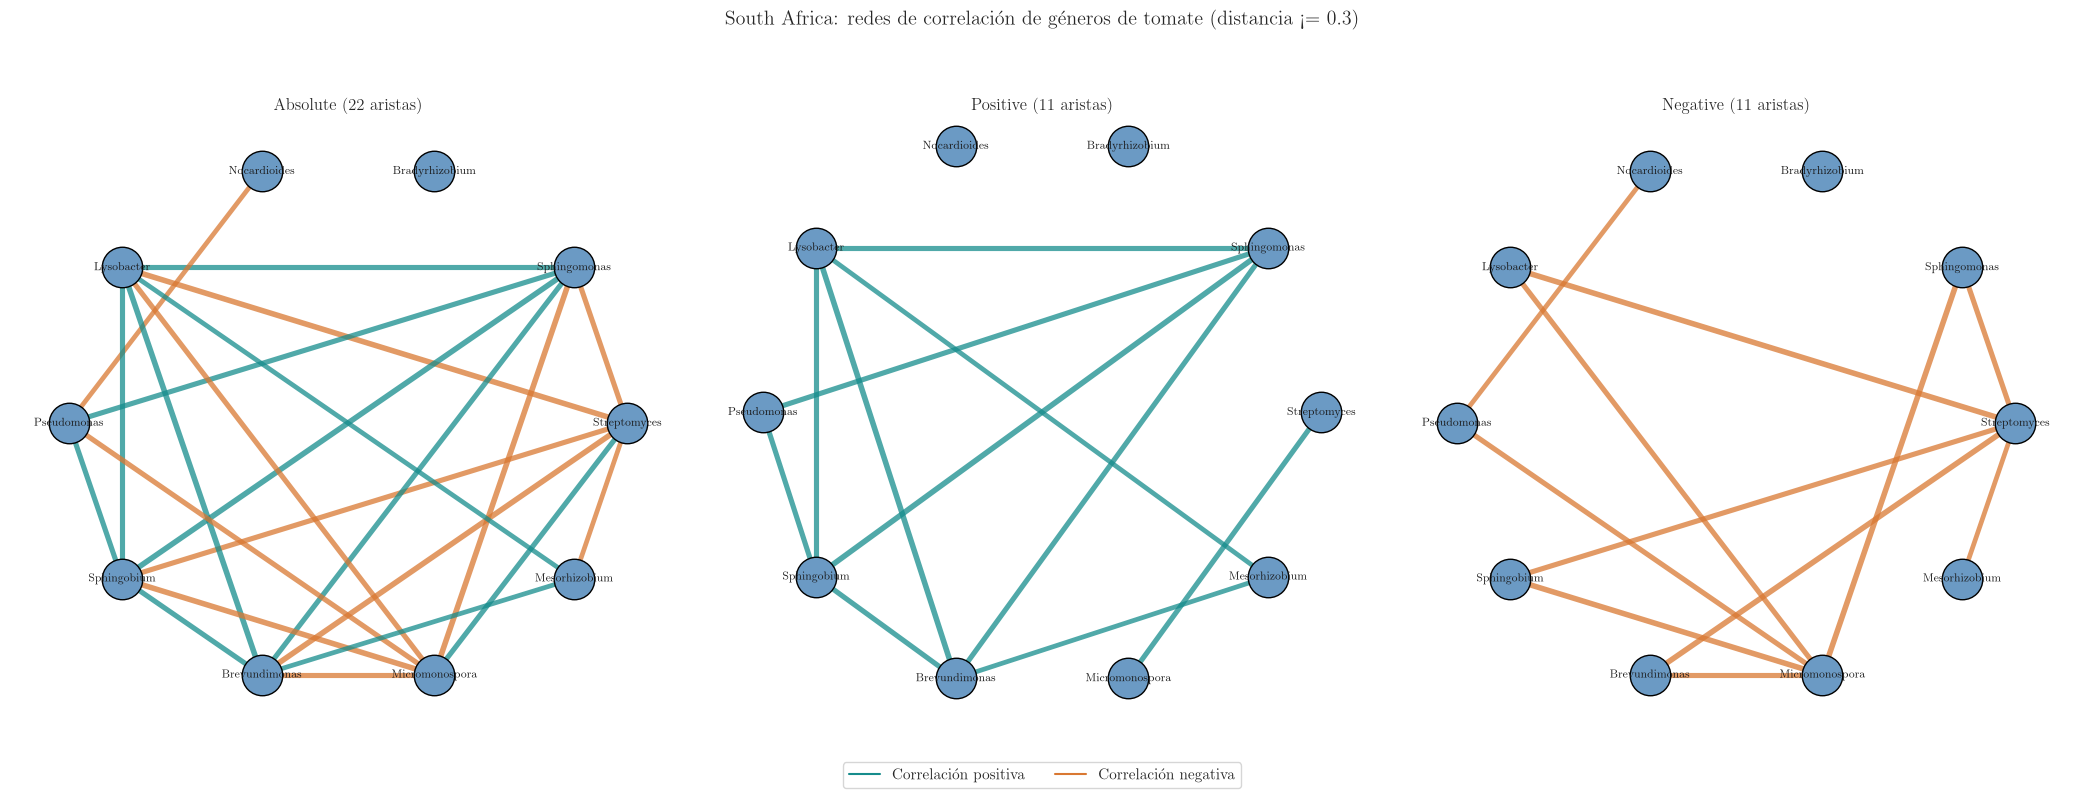

South Africa: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Corr_Spearman/Networks/Tomato_top10/South_Africa/South_Africa_correlation_networks.png


In [24]:
#| label: l4-coocurrence_graphs
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
# Propósito: construir los tres grafos de correlación de un país con un umbral configurable.
# Por defecto la página muestra solo South Africa; countries_to_plot permite ampliar el ejemplo.
max_correlation_distance = 0.3
network_output_root = Path(workdir) / "Corr_Spearman" / "Networks" / "Tomato_top10"

country_correlation_data = {
    "South Africa": {
        "correlation": corr_matrix_south_africa,
        "distances": {
            "absolute": corr_matrix_abs_south_africa,
            "positive": corr_matrix_pos_south_africa,
            "negative": corr_matrix_neg_south_africa,
        },
    }
}
country_correlation_data.update({
    country_name: {
        "correlation": result["correlation"],
        "distances": result["distance_matrices"],
    }
    for country_name, result in correlation_results_by_country.items()
})

def build_correlation_graphs(country_name, country_data, threshold):
    correlation = country_data["correlation"]
    distances = country_data["distances"]
    genera = correlation.index
    graph_types = ["absolute", "positive", "negative"]
    graphs = {}
    layout_graph = nx.Graph()
    layout_graph.add_nodes_from(genera)

    for graph_type in graph_types:
        matrix = distances[graph_type]
        graph = nx.Graph(country=country_name, correlation_type=graph_type)
        graph.add_nodes_from(genera)
        for genus_a, genus_b in combinations(genera, 2):
            distance = matrix.loc[genus_a, genus_b]
            rho = correlation.loc[genus_a, genus_b]
            if pd.notna(distance) and pd.notna(rho) and distance <= threshold:
                graph.add_edge(
                    genus_a, genus_b,
                    distance=float(distance),
                    correlation=float(rho),
                    weight=float(abs(rho)),
                )
                layout_graph.add_edge(genus_a, genus_b, weight=float(abs(rho)))
        graphs[graph_type] = graph
    return graphs, nx.circular_layout(layout_graph, scale=2.2)

def plot_correlation_graphs(country_name, country_data, threshold):
    graphs, positions = build_correlation_graphs(country_name, country_data, threshold)
    graph_types = ["absolute", "positive", "negative"]
    fig, axes = plt.subplots(1, 3, figsize=(21, 8))

    for ax, graph_type in zip(axes, graph_types):
        graph = graphs[graph_type]
        if graph.number_of_edges():
            nx.draw_networkx_edges(
                graph, positions, ax=ax,
                edge_color=[
                    "#168C8C" if graph[u][v]["correlation"] >= 0 else "#D97832"
                    for u, v in graph.edges
                ],
                width=[1 + 3 * graph[u][v]["weight"] for u, v in graph.edges],
                alpha=0.75,
            )
        nx.draw_networkx_nodes(
            graph, positions, ax=ax, node_size=850,
            node_color="#6B9AC4", edgecolors="black"
        )
        nx.draw_networkx_labels(graph, positions, ax=ax, font_size=8)
        ax.set_title(f"{graph_type.capitalize()} ({graph.number_of_edges()} aristas)")
        ax.axis("off")

    fig.suptitle(
        f"{country_name}: redes de correlación de géneros de tomate "
        f"(distancia <= {threshold})"
    )
    fig.legend(
        handles=[
            plt.Line2D([], [], color="#168C8C", label="Correlación positiva"),
            plt.Line2D([], [], color="#D97832", label="Correlación negativa"),
        ],
        loc="lower center", ncol=2
    )
    fig.tight_layout(rect=[0, 0.06, 1, 0.94])

    country_slug = re.sub(r"[^A-Za-z0-9_-]+", "_", country_name).strip("_")
    output_dir = network_output_root / country_slug
    output_dir.mkdir(parents=True, exist_ok=True)
    graph_path = output_dir / f"{country_slug}_correlation_networks.png"
    fig.savefig(graph_path, bbox_inches="tight", dpi=180)
    plt.show()
    plt.close(fig)
    print(f"{country_name}: {graph_path}")
    return graphs

# El capítulo muestra únicamente South Africa. Cambia o amplía esta lista para el ejercicio.
countries_to_plot = ["South Africa"]
correlation_networks_by_country = {
    country: plot_correlation_graphs(
        country, country_correlation_data[country], max_correlation_distance
    )
    for country in countries_to_plot
}


::: {.callout-tip}
### Solución del instructor — Ejercicio 2: grafos de los demás países
Reutilizamos la función anterior y generamos China, Mexico y Netherlands. Las posiciones y los nodos son comparables porque todos los países usan `selected_genera`.
:::


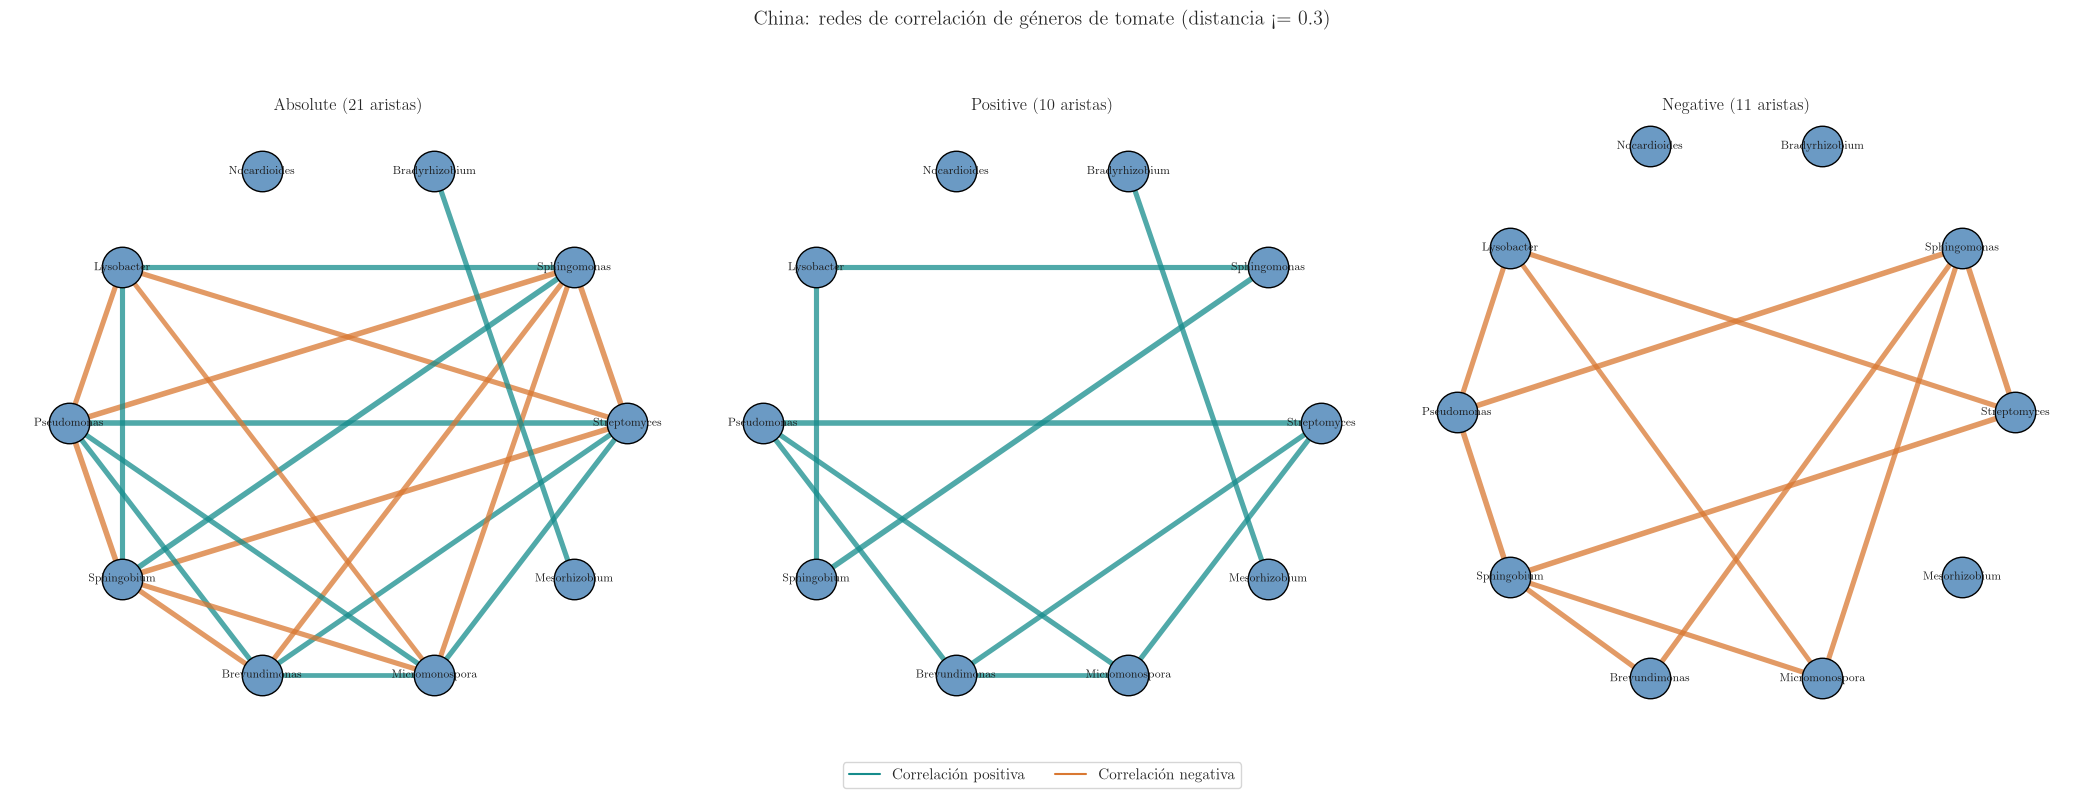

China: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Corr_Spearman/Networks/Tomato_top10/China/China_correlation_networks.png


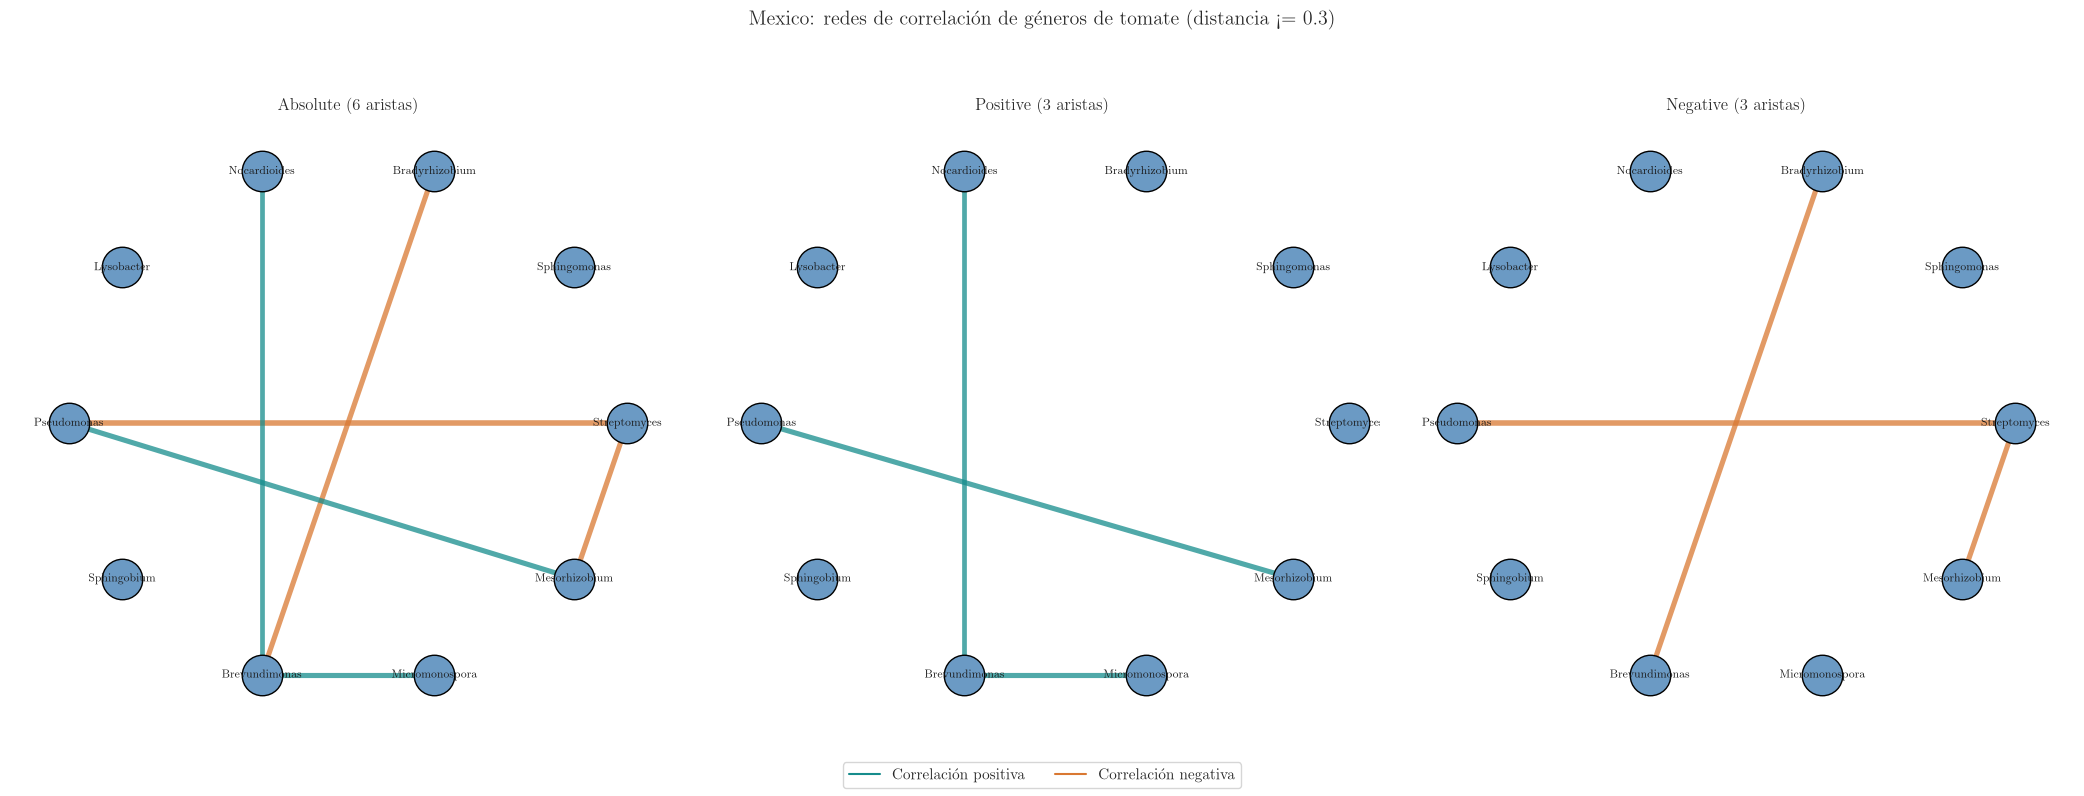

Mexico: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Corr_Spearman/Networks/Tomato_top10/Mexico/Mexico_correlation_networks.png


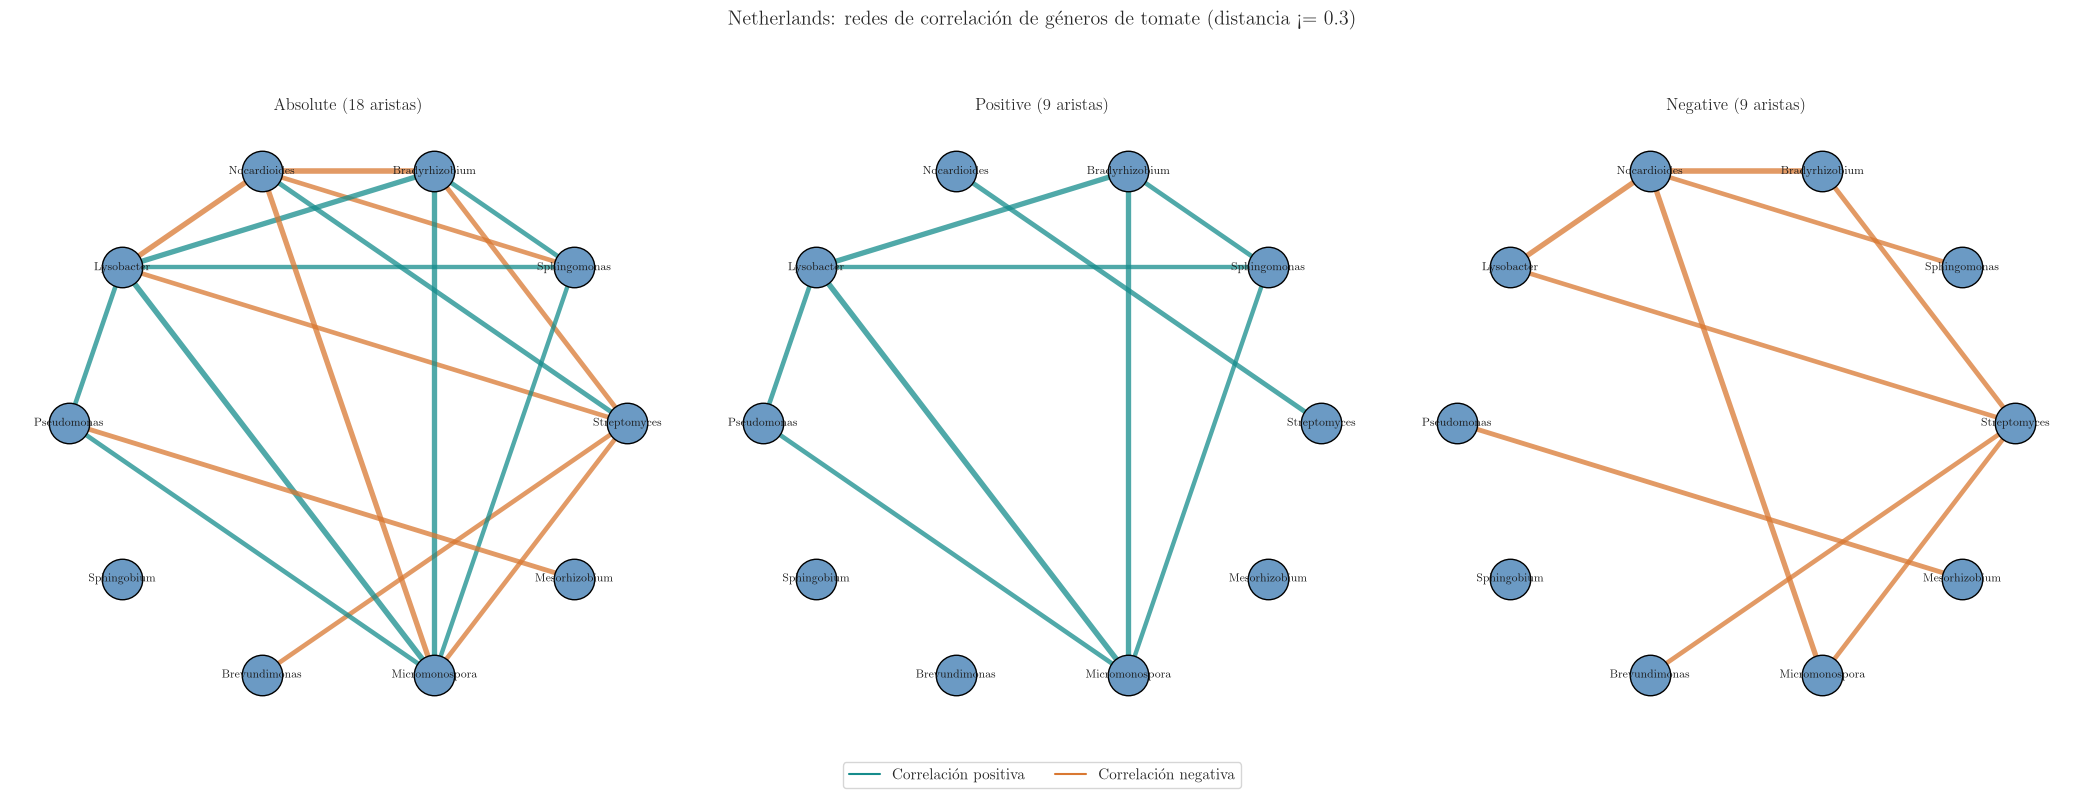

Netherlands: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Corr_Spearman/Networks/Tomato_top10/Netherlands/Netherlands_correlation_networks.png


,country,type,nodes,edges,components,density
0,South Africa,absolute,10,22,2,0.488889
1,South Africa,positive,10,11,4,0.244444
2,South Africa,negative,10,11,2,0.244444
3,China,absolute,10,21,3,0.466667
4,China,positive,10,10,4,0.222222
5,China,negative,10,11,4,0.244444
6,Mexico,absolute,10,6,5,0.133333
7,Mexico,positive,10,3,7,0.066667
8,Mexico,negative,10,3,7,0.066667
9,Netherlands,absolute,10,18,2,0.400000


In [25]:
# Propósito: resolver el Ejercicio 2 generando los países restantes y resumiendo sus redes.
# La tabla reporta nodos, aristas, componentes y densidad, sin interpretar las aristas como interacciones biológicas.
for country in countries_to_process:
    correlation_networks_by_country[country] = plot_correlation_graphs(
        country, country_correlation_data[country], max_correlation_distance
    )

network_summary = []
for country, graphs in correlation_networks_by_country.items():
    for graph_type, graph in graphs.items():
        network_summary.append({
            "country": country,
            "type": graph_type,
            "nodes": graph.number_of_nodes(),
            "edges": graph.number_of_edges(),
            "components": nx.number_connected_components(graph),
            "density": nx.density(graph),
        })
pd.DataFrame(network_summary)


## 9. Homología persistente de las redes de coocurrencia

Aplicamos Vietoris-Rips a cada una de las tres transformaciones de Spearman.


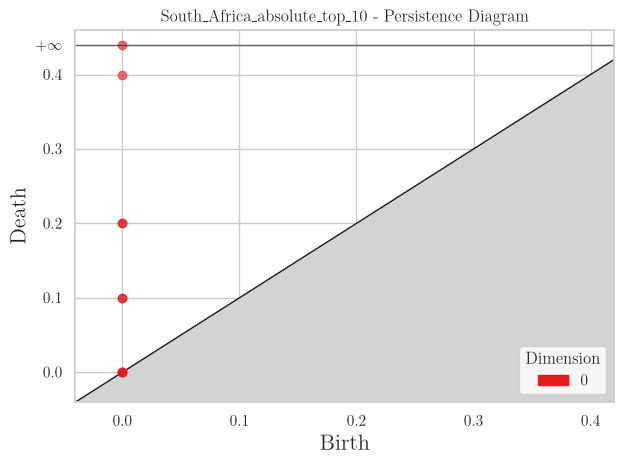

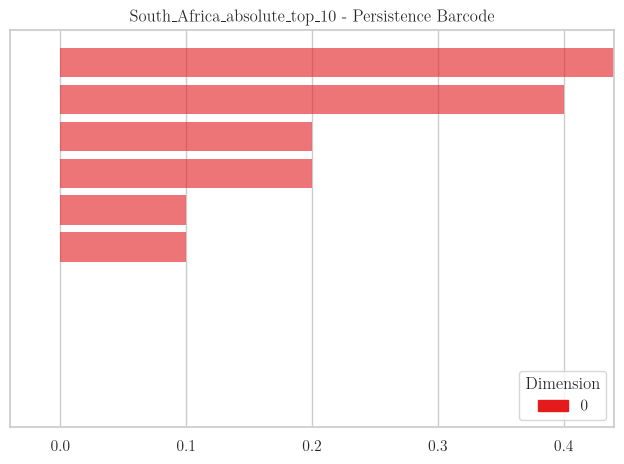

Diagrama guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/South_Africa_absolute_top_10_persistence_diagram.png
Código de barras guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/South_Africa_absolute_top_10_persistence_barcode.png


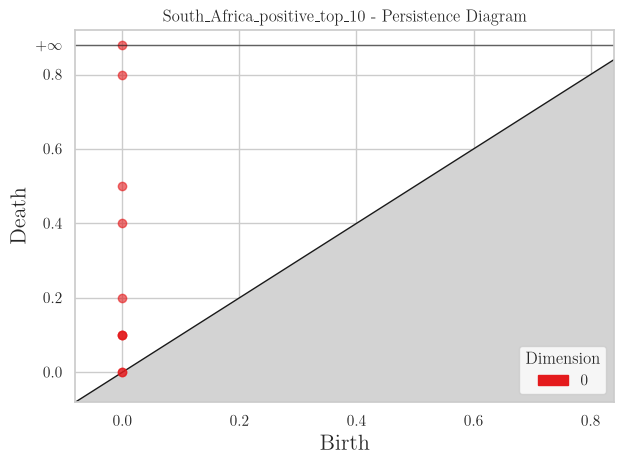

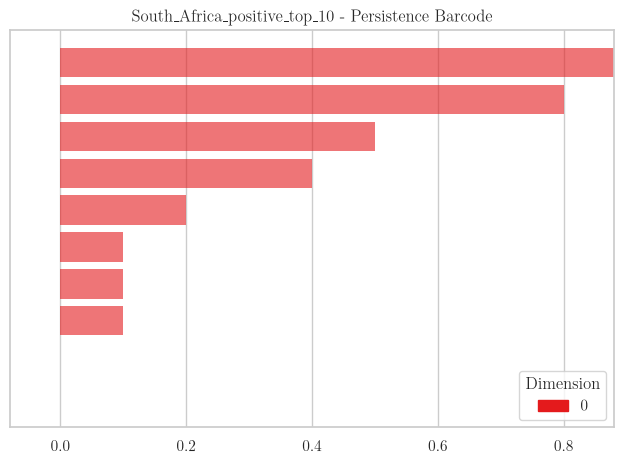

Diagrama guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/South_Africa_positive_top_10_persistence_diagram.png
Código de barras guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/South_Africa_positive_top_10_persistence_barcode.png


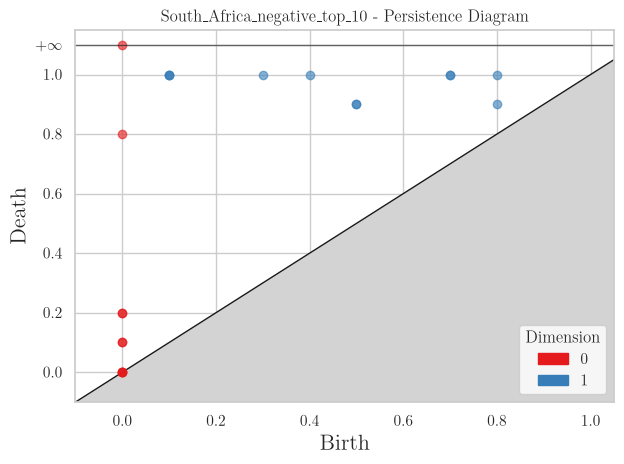

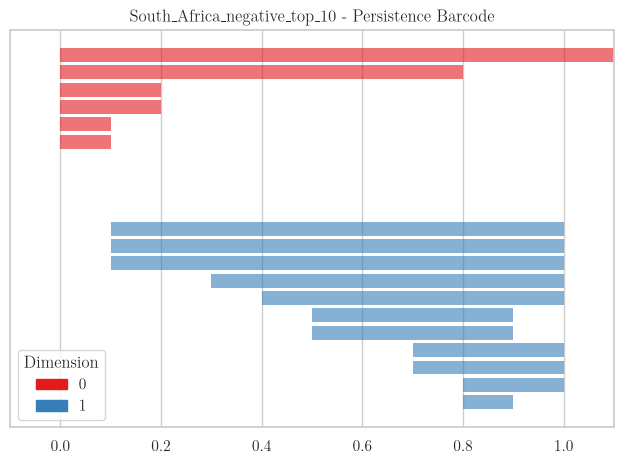

Diagrama guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/South_Africa_negative_top_10_persistence_diagram.png
Código de barras guardado en: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Diagramas_Persistencia/South_Africa_negative_top_10_persistence_barcode.png
Diagramas generados: 3


In [26]:
#| label: l4-TDA-corr-distance-matrices-south-africa
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
# Propósito: calcular la homología persistente de las tres redes de South Africa.
south_africa_distance_matrices = {
    "absolute": corr_matrix_abs_south_africa,
    "positive": corr_matrix_pos_south_africa,
    "negative": corr_matrix_neg_south_africa,
}
persistence_south_africa_by_type = {}

for correlation_type, distance_matrix in south_africa_distance_matrices.items():
    persistence_south_africa_by_type[correlation_type] = create_complex(
        distance_matrix.to_numpy(),
        label=f"South_Africa_{correlation_type}_top_{len(selected_genera)}"
    )

print(f"Diagramas generados: {len(persistence_south_africa_by_type)}")


::: {.callout-tip}
### Solución del instructor — Ejercicio 3: topología por país
Resumimos cuántas clases finitas de (H_0) y (H_1) aparecen en cada transformación. Esta tabla orienta la comparación, pero no establece diferencias biológicas.
:::


In [27]:
# Propósito: resolver el Ejercicio 3 resumiendo clases topológicas finitas por país y transformación.
# H0, H1 y H2 describen componentes, ciclos y cavidades; el conteo no establece significación biológica.
all_persistence = {"South Africa": persistence_south_africa_by_type}
all_persistence.update({
    country: result["persistence"]
    for country, result in correlation_results_by_country.items()
})

persistence_summary = []
for country, persistence_by_type in all_persistence.items():
    for correlation_type, (_, simplex_tree) in persistence_by_type.items():
        persistence = simplex_tree.persistence()
        persistence_summary.append({
            "country": country,
            "correlation": correlation_type,
            "H0_finite": sum(
                1 for dim, (birth, death) in persistence
                if dim == 0 and np.isfinite(death)
            ),
            "H1_finite": sum(
                1 for dim, (birth, death) in persistence
                if dim == 1 and np.isfinite(death)
            ),
            "H2_finite": sum(
                1 for dim, (birth, death) in persistence
                if dim == 2 and np.isfinite(death)
            ),
        })
pd.DataFrame(persistence_summary).sort_values(["country", "correlation"])


,country,correlation,H0_finite,H1_finite,H2_finite
3,China,absolute,9,1,0
5,China,negative,9,10,0
4,China,positive,9,0,0
6,Mexico,absolute,9,1,0
8,Mexico,negative,9,7,0
7,Mexico,positive,9,1,0
9,Netherlands,absolute,7,2,0
11,Netherlands,negative,8,10,0
10,Netherlands,positive,8,0,0
0,South Africa,absolute,9,0,0


## 10. Comparación de diagramas de persistencia entre países

La distancia de Wasserstein cuantifica el costo mínimo de transformar un diagrama en otro. Aquí se utiliza como una comparación descriptiva; no mide por sí sola similitud ecológica.


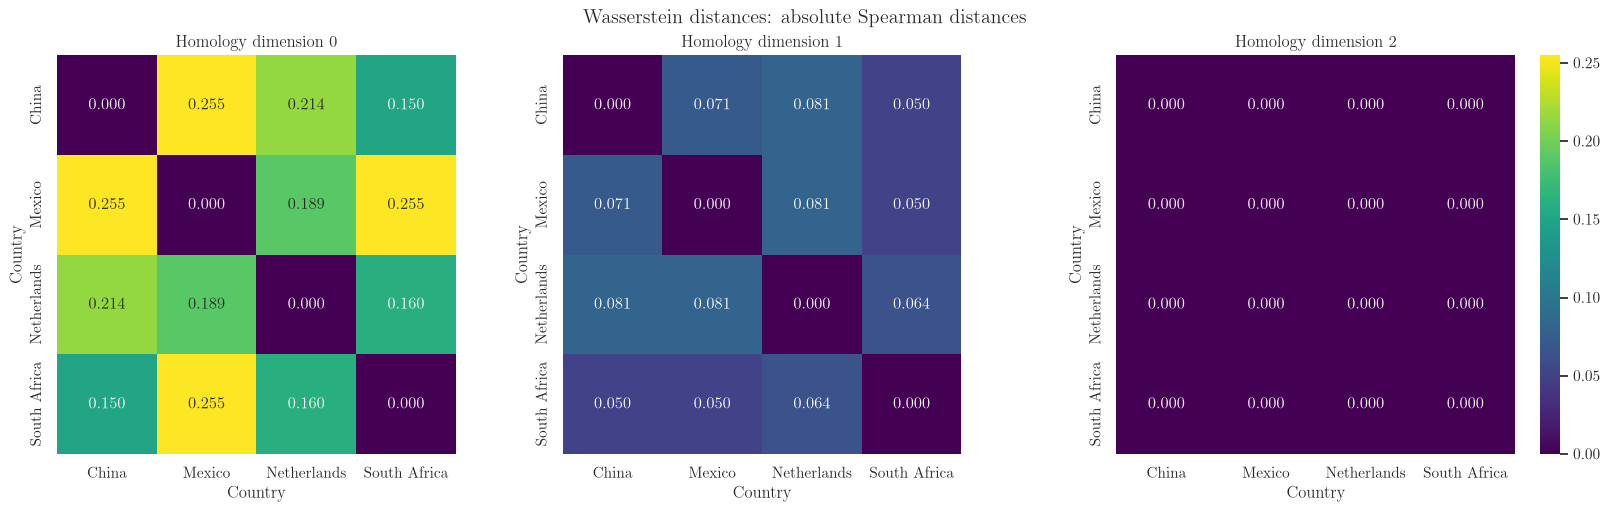

absolute: saved heatmap to /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Corr_Spearman/South_Africa/Wasserstein/Tomato_top10/wasserstein_absolute_top10.jpg


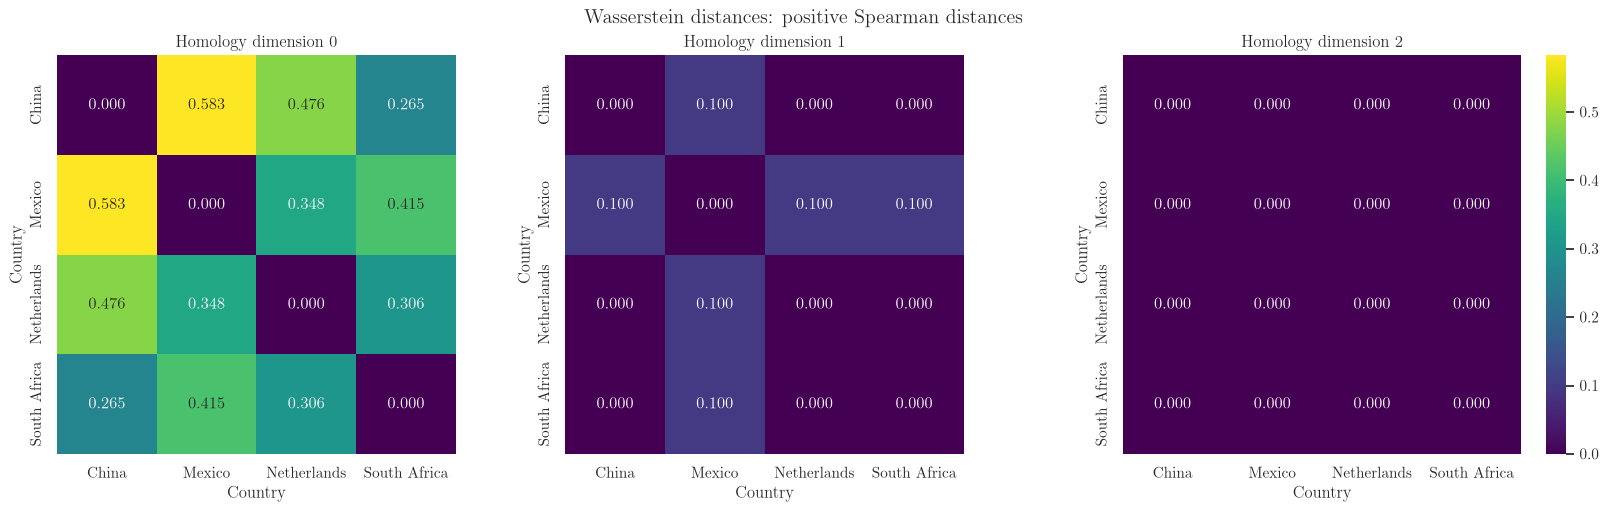

positive: saved heatmap to /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Corr_Spearman/South_Africa/Wasserstein/Tomato_top10/wasserstein_positive_top10.jpg


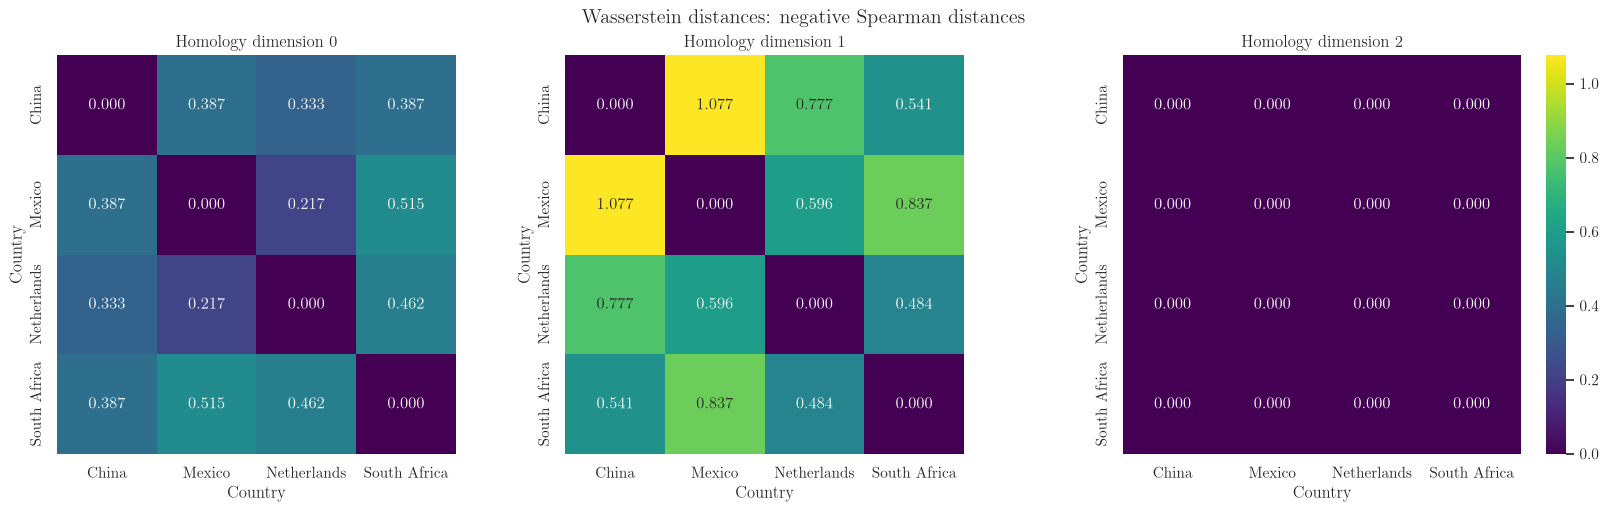

negative: saved heatmap to /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Corr_Spearman/South_Africa/Wasserstein/Tomato_top10/wasserstein_negative_top10.jpg
Countries compared: ['China', 'Mexico', 'Netherlands', 'South Africa']
Wasserstein matrices saved to: /Users/alejandroucan/Documents/GitHub/MicroAgroBiome_bioinfo2026_libro/resultados/leccion_4_tda/Corr_Spearman/South_Africa/Wasserstein/Tomato_top10


In [28]:
#| label: l4-wasserstein-distance
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
# Propósito: comparar diagramas de persistencia entre países mediante distancia de Wasserstein.
# Solo se comparan puntos con muerte finita y se requiere al menos un segundo país para construir una matriz.

from gudhi.hera import wasserstein_distance

# South Africa se analiza en el ejemplo principal. Los demás países solo se
# incorporan si el estudiante los agrega a countries_to_process.
country_persistence = {}
if "persistence_south_africa_by_type" in globals():
    country_persistence["South Africa"] = {
        distance_type: result[0]
        for distance_type, result in persistence_south_africa_by_type.items()
    }

for country_name, result in correlation_results_by_country.items():
    country_persistence[country_name] = {
        distance_type: persistence_result[0]
        for distance_type, persistence_result in result["persistence"].items()
    }

country_names = sorted(country_persistence)
if len(country_names) < 2:
    print(
        "La distancia de Wasserstein requiere al menos dos países. "
        "Agrega países a countries_to_process y vuelve a ejecutar las celdas "
        "de análisis antes de esta comparación."
    )
else:
    correlation_types = ["absolute", "positive", "negative"]
    homology_dimensions = [0, 1, 2]
    wasserstein_matrices = {}

    for correlation_type in correlation_types:
        for dimension in homology_dimensions:
            distance_matrix = pd.DataFrame(
                0.0,
                index=country_names,
                columns=country_names
            )
            diagrams = {}
            for country_name in country_names:
                diagram = country_persistence[country_name][correlation_type]
                finite_points = [
                    point for dim, point in diagram
                    if dim == dimension and np.isfinite(point).all()
                ]
                diagrams[country_name] = np.asarray(
                    finite_points, dtype=float
                ).reshape(-1, 2)

            for i, country_a in enumerate(country_names):
                for country_b in country_names[i + 1:]:
                    diagram_a = diagrams[country_a]
                    diagram_b = diagrams[country_b]
                    if len(diagram_a) == 0 and len(diagram_b) == 0:
                        distance = 0.0
                    else:
                        distance = wasserstein_distance(
                            diagram_a, diagram_b, order=2
                        )
                    distance_matrix.loc[country_a, country_b] = distance
                    distance_matrix.loc[country_b, country_a] = distance

            wasserstein_matrices[(correlation_type, dimension)] = distance_matrix

    wasserstein_output_dir = os.path.join(
        corr_output_dir, "Wasserstein", "Tomato_top10"
    )
    os.makedirs(wasserstein_output_dir, exist_ok=True)

    for correlation_type in correlation_types:
        fig, axes = plt.subplots(
            1, len(homology_dimensions), figsize=(16, 5), constrained_layout=True
        )
        max_distance = max(
            wasserstein_matrices[(correlation_type, dimension)].to_numpy().max()
            for dimension in homology_dimensions
        )
        vmax = max_distance if max_distance > 0 else 1.0

        for ax, dimension in zip(axes, homology_dimensions):
            matrix = wasserstein_matrices[(correlation_type, dimension)]
            matrix.to_csv(
                os.path.join(
                    wasserstein_output_dir,
                    f"wasserstein_{correlation_type}_dimension_{dimension}.csv"
                )
            )
            sns.heatmap(
                matrix,
                annot=True,
                fmt=".3f",
                cmap="viridis",
                vmin=0,
                vmax=vmax,
                square=True,
                ax=ax,
                cbar=ax is axes[-1]
            )
            ax.set_title(f"Homology dimension {dimension}")
            ax.set_xlabel("Country")
            ax.set_ylabel("Country")

        fig.suptitle(
            f"Wasserstein distances: {correlation_type} Spearman distances"
        )
        figure_path = os.path.join(
            wasserstein_output_dir,
            f"wasserstein_{correlation_type}_top10.jpg"
        )
        fig.savefig(figure_path, bbox_inches="tight", dpi=180)
        plt.show()
        plt.close(fig)
        print(f"{correlation_type}: saved heatmap to {figure_path}")

    print(f"Countries compared: {country_names}")
    print(f"Wasserstein matrices saved to: {wasserstein_output_dir}")


# 11. Discusión y conclusiones

## Qué podemos concluir

- **Muestras:** Bray-Curtis resume diferencias de composición. Las redes muestran cómo cambia la conectividad al variar el umbral.
- **Géneros:** Spearman explora asociaciones monotónicas dentro de cada país; las aristas no representan interacciones demostradas.
- **TDA:** los diagramas describen componentes, ciclos y su persistencia bajo una filtración.
- **Wasserstein:** permite comparar diagramas con la misma transformación y el mismo conjunto de géneros, sin establecer significación biológica.

## Limitaciones

1. Tamaños de muestra pequeños y desiguales.
2. Naturaleza composicional de las abundancias relativas.
3. Posibles variables de confusión y diferencias metodológicas entre estudios.
4. Elección de nivel taxonómico, métrica y umbrales.
5. Las comparaciones topológicas son exploratorias y no causales.
